# Latent tasks (was notebooks/141_latent_tasks.ipynb)
A small toolkit for latent arithmetic on one trained run, redoing the nb139 analogies cleanly.
**Combine objects**: ½·obj1 at p1 + ½·obj2 at p2 + c = the obj1+obj2 pair, where c = mean pair − ½(mean obj1 + mean obj2) (leave-one-out).
**Swap objects**: obj1 at p − mean obj1 + mean obj2 = obj2 at p.
Notation: ẑ = predicted latent, z = latent of the true target, Î = decoder(ẑ) > 0.08, I = the target's label.
Rank = 1 + the number of wrong candidates closer than the true target. The candidates are the target object's recordings in the same box and speaker; other recordings at the target's own position are dropped.

## Config

In [1]:
import os, sys, json, functools, itertools, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())  # repo root, from wherever the notebook runs
sys.path.insert(0, str(ROOT / "src9"))

RUN = os.environ.get("RUN", "decres-rescale-aug10-v1")
CACHE = ROOT / "runs/_src9_cache/nb141" / RUN; CACHE.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "figures/latent_tasks"  # final figures: figure_latent_tasks_<name>_<k>_<kind>.svg
TH, R_PX, BAD = 0.08, 2.0, "shifted|unseen-speaker|lid"  # mask threshold · "same position" radius (px, 64×64 frame) · splits left out of the tasks
OBJS = ["red-cube", "soap dispenser", "candle", "vase"]
PAIRS = {"red-cube+vase": [("red-cube", "red-cube0"), ("vase", "vase0")], "green-cube+red-cube": [("red-cube", "green-cube0"), ("red-cube", "red-cube0")]}  # pair → (object, instance mask) per part
ICON = {"red-cube": "cube", "vase": "vase", "candle": "candle", "soap dispenser": "soap", "red-cube+vase": "cube_and_vase", "green-cube+red-cube": "two_cubes"}
BOXES = {"2026_09_27_gastronorm_four_objs": "gastro", "2026_10_05_green_plastic_four_objs": "plastic", "2026_10_11_cardboard_four_objs": "cardboard"}
PRED = "#E6A700"  # the prediction's colour
NAME = {"combine": "combine_objects", "swap": "swap_objects"}  # figure names: figure_latent_tasks_<name>_<k>_<kind>.svg

## Model: Transformer4 from args.json, latest checkpoint, eager fp32 (no torch.compile: its no_grad eval gave wrong masks)

In [2]:
@functools.cache
def load_model(run=RUN):
    from dataset import build_dataset
    from arch.transformer4 import Transformer4
    torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
    a = json.load(open(ROOT / "runs" / run / "args.json")); assert a["model"] == "transformer4", a["model"]
    _, ev, tr, info = build_dataset(a.get("window", "tukey"), num_workers=0)
    model = Transformer4(info, decoder=a.get("decoder", "two"), latent_norm=a.get("latent_norm", "ln"), freq_rope=a.get("freq_rope", "linear"),
                         spk_grl_w=a.get("spk_grl_w") or 0, adapter_dim=a.get("adapter_dim") or 0)
    sd = torch.load(ROOT / "runs" / run / "checkpoints/latest-rank0.pt", map_location="cpu", weights_only=False)["state"]["model"]
    print(model.load_state_dict(sd))
    splits = [("train", tr.dataloader.dataloader.dataset)] + [(e.label, e.dataloader.dataloader.dataset) for e in ev]  # (name, Subset)
    return model.cuda().eval(), splits

## Encoder: one pass over every sample → latents.npy (fp32), masks_pred.npy, masks_gt.npy, meta.parquet

In [3]:
def com(mask):  # (x, y) = (col, row) centre of mass in the 64×64 frame, nan if empty
    r, c = np.nonzero(mask); return (c.mean(), r.mean()) if len(r) else (np.nan, np.nan)

def part_com(d, inst):  # one object's centre inside a pair recording, from its full-resolution instance mask
    m = np.load(Path(d) / f"image/smasks/{inst}.npy") > 0; r, c = np.nonzero(m)
    return (c.mean() + .5) * 64 / m.shape[1] - .5, (r.mean() + .5) * 64 / m.shape[0] - .5

def run_encoder(run=RUN, bs=128):
    if (CACHE / "meta.parquet").exists(): return pd.read_parquet(CACHE / "meta.parquet"), np.load(CACHE / "latents.npy")
    model, splits = load_model(run)
    jobs = [(name, sub.dataset, i) for name, sub in splits for i in sub.indices]
    U, P, Y, rows = [], [], [], []
    with torch.no_grad():
        for s in range(0, len(jobs), bs):
            batch = [(name, ds, ds[i], ds.metas[i]) for name, ds, i in jobs[s:s + bs]]
            out = model(dict(fft=torch.stack([b["fft"] for _, _, b, _ in batch]).cuda()))
            U.append(out["latent"].float().cpu().numpy()); P.append(out["mask_pred"].float().cpu().numpy())
            Y.append(np.stack([(b["mask_true"] > .5).numpy() for _, _, b, _ in batch]).astype(np.uint8))
            rows += [dict(split=name, box=BOXES[m["experiment"]], object="+".join(sorted(m["objects"])) or "empty", speaker=int(m["speaker"]), pos=int(m["position_id"]),
                          dir=str(ROOT / "experiments" / m["experiment"] / "samples" / m["sample_id"])) for name, _, _, m in batch]
            if s % (20 * bs) == 0: print(f"{s}/{len(jobs)}", flush=True)
    U, P, Y = np.concatenate(U), np.concatenate(P), np.concatenate(Y)
    meta = pd.DataFrame(rows); meta.index.name = "row"
    meta["sid"] = meta.pos.astype(str) + "-" + meta.speaker.astype(str)
    meta[["x", "y"]] = [com(m) for m in Y]; meta["area"] = Y.sum((1, 2))
    meta["photo"] = meta.dir + "/image/02_cropped_overhead.png"
    for pair, parts in PAIRS.items():
        ix = meta.index[meta.object == pair]
        for j, (_, inst) in enumerate(parts): meta.loc[ix, [f"x{j}", f"y{j}"]] = [part_com(d, inst) for d in meta.dir[ix]]
    np.save(CACHE / "latents.npy", U); np.save(CACHE / "masks_pred.npy", P); np.save(CACHE / "masks_gt.npy", Y); meta.to_parquet(CACHE / "meta.parquet")
    return meta, U

## Decoder: (N, 512) latents → soft masks, same fp32 path and batch size as the forward pass

In [4]:
def run_decoder(Z, bs=128):
    dec = load_model()[0].decoder
    with torch.no_grad():
        return np.concatenate([dec(torch.from_numpy(np.ascontiguousarray(Z[s:s + bs], np.float32)).cuda()).sigmoid().cpu().numpy() for s in range(0, len(Z), bs)])

## PCA: one 2-D PCA over all latents, applied linearly (x @ W, no centring) so tip-to-tail sums stay exact

In [5]:
def pca2d(Z):
    f = CACHE / "pca2d.npz"
    if not f.exists():
        A = np.load(CACHE / "latents.npy").astype(np.float64); mean = A.mean(0)
        np.savez(f, W=np.linalg.svd(A - mean, full_matrices=False)[2][:2].T, mean=mean)
    return np.asarray(Z, np.float64) @ np.load(f)["W"]

## Load the caches (the first run encodes everything, a few minutes on the GPU)

In [6]:
META, Z = run_encoder()
D = META[~META.split.str.contains(BAD)]  # the rows the tasks may use
EMPTY = {b: g.index[0] for b, g in D[D.object == "empty"].groupby("box")}  # one empty-box recording per box: its photo stands for "the box"
print(len(META), "samples,", len(D), "usable;", Z.shape, Z.dtype)
D.groupby(["box", "object"]).size().unstack(0)

15891 samples, 15132 usable; (15891, 512) float32


box,cardboard,gastro,plastic
object,,,
biscoff,36.0,NaN,NaN
candle,1147.0,778.0,1011.0
coffee pot,36.0,24.0,343.0
cylinder-1000g,135.0,27.0,32.0
cylinder-100g,171.0,6.0,28.0
cylinder-200g,193.0,NaN,35.0
cylinder-500g,199.0,27.0,32.0
empty,73.0,36.0,60.0
glass-cup,120.0,NaN,NaN


## Check: run_decoder(latents) reproduces the model's own mask_pred

In [7]:
P = np.load(CACHE / "masks_pred.npy", mmap_mode="r")
err = np.abs(run_decoder(Z[:1024]) - P[:1024]).max()
rnd = np.sort(np.random.default_rng(0).choice(len(Z), 512, replace=False)); err_rnd = np.abs(run_decoder(Z[rnd]) - P[rnd]).max()
print(f"max |decoder(latent) − mask_pred|: same batches {err:.1e}, random rows {err_rnd:.1e}")
assert err == 0 and err_rnd < 1e-4  # same batches: bit-exact; other batch compositions: cuDNN picks other conv algorithms (~1e-5)

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

<All keys matched successfully>


max |decoder(latent) − mask_pred|: same batches 0.0e+00, random rows 1.3e-05


## Tasks: one (box, speaker) group G and one target row t → terms [(name, coef, latent, image ref)], ẑ, target, candidates, cosine centre

In [8]:
def candidates(G, t):  # the target object's recordings in G, and which of them sit at the target's position (≤ R_PX; pairs: both parts)
    P_ = G[G.object == META.object[t]]
    cols = [["x0", "y0"], ["x1", "y1"]] if META.object[t] in PAIRS else [["x", "y"]]
    d = np.max([np.hypot(*(P_[c].values - META.loc[t, c].values.astype(float)).T) for c in cols], 0)
    return P_.index, d <= R_PX

def result(terms, t, G, ctr):
    cands, same = candidates(G, t)
    return dict(terms=terms, zh=sum(c * z for _, c, z, _ in terms), target=t, cands=cands, same=same, ctr=ctr)

def nearest(S, x, y): d = np.hypot(S.x - x, S.y - y); return d.idxmin(), d.min()

def combine(G, t):  # ½·obj1 at p1 + ½·obj2 at p2 + c = pair
    r = META.loc[t]; (o1, _), (o2, _) = PAIRS[r.object]
    s1, s2 = G[G.object == o1], G[G.object == o2]
    (u, _), (v, _) = nearest(s1, r.x0, r.y0), nearest(s2, r.x1, r.y1)
    mp = Z[G.index[(G.object == r.object) & (G.index != t)]].mean(0)  # leave-one-out mean pair
    c = mp - .5 * (Z[s1.index].mean(0) + Z[s2.index].mean(0))
    return result([(f"{o1} at p1", .5, Z[u], ("photo", u)), (f"{o2} at p2", .5, Z[v], ("photo", v)), ("c", 1., c, ("c",))], t, G, mp)

def swap(G, t, obj1):  # obj1 at p − mean obj1 + mean obj2 = obj2 at p
    r = META.loc[t]; s1 = G[G.object == obj1]; src, d = nearest(s1, r.x, r.y)
    if d > R_PX: return None
    m2 = Z[G.index[(G.object == r.object) & (G.index != t)]].mean(0)
    return result([(f"{obj1} at p", 1., Z[src], ("photo", src)), (f"mean {obj1}", -1., Z[s1.index].mean(0), ("icon", obj1)), (f"mean {r.object}", 1., m2, ("icon", r.object))], t, G, m2)

TASKS = {  # task → (function, the (target, kwargs) list of a group)
    "combine": (combine, lambda G: [(t, {}) for t in G.index[G.object.isin(list(PAIRS))]]),
    "swap": (swap, lambda G: [(t, dict(obj1=o)) for o in OBJS for t in G.index[G.object.isin(OBJS) & (G.object != o)]]),
}

def group(box, speaker): return D[(D.box == box) & (D.speaker == speaker)]
def instance(row): return TASKS[row.task][0](group(row.box, row.speaker), row.target, **json.loads(row.kw))  # rebuild one df row's task

## Search: every (box, speaker) group and target → cos / L2 / L1 in the latent, IoU / CoM of Î against the candidates' labels, and their ranks
Two rank rules. **exact** (the main one): only the target is true, and the other recordings at its position are dropped from the candidates.
**any** (nb139's rule): a hit counts if any recording at the target's position (≤ R_PX) is the closest.

In [9]:
unit = lambda X: X / np.linalg.norm(X, axis=-1, keepdims=True)
def rank(s, true, lower=False):  # 1 + wrong candidates closer than the best true one
    b = s[true].min() if lower else s[true].max(); return 1 + int(((s[~true] < b) if lower else (s[~true] > b)).sum())

def search(task):
    f = CACHE / f"search_{task}.parquet"
    if f.exists(): return pd.read_parquet(f)
    fn, targets = TASKS[task]; R = []
    for (box, spk), G in D.groupby(["box", "speaker"]):
        for t, kw in targets(G):
            r = fn(G, t, **kw)
            if r is not None: R.append((box, spk, kw, r))
    Ih = run_decoder(np.stack([r["zh"] for *_, r in R])) > TH
    np.save(CACHE / f"search_{task}_pred.npy", np.packbits(Ih.reshape(len(Ih), -1), 1))
    GT, rows = np.load(CACHE / "masks_gt.npy", mmap_mode="r"), []
    for k, (box, spk, kw, r) in enumerate(R):
        C, t, ctr, same = r["cands"], r["target"], r["ctr"], r["same"]; zc, is_t = Z[C], C.values == t
        ex = ~same | is_t  # exact: the other same-position recordings are dropped; any: all of them count as true
        cos = unit(zc - ctr) @ unit(r["zh"] - ctr); l2 = np.linalg.norm(zc - r["zh"], axis=1); l1 = np.abs(zc - r["zh"]).sum(1)
        g = GT[C] > 0; iou = (g & Ih[k]).sum((1, 2)) / np.maximum((g | Ih[k]).sum((1, 2)), 1)
        dc = np.nan_to_num(np.hypot(*(META.loc[C, ["x", "y"]].values - com(Ih[k])).T), nan=np.inf)
        i, true = np.flatnonzero(is_t)[0], is_t[ex]
        rows.append(dict(task=task, box=box, speaker=spk, obj1=kw.get("obj1", META.object[t].split("+")[0]), obj2=META.object[t], target=t, sid=META.sid[t],
                         terms=",".join(str(ref[1]) for *_, ref in r["terms"] if ref[0] == "photo"), kw=json.dumps(kw), n=int(ex.sum()), n_any=len(C),
                         cos=cos[i], l2=l2[i], l1=l1[i], iou=iou[i], com=dc[i], rank_cos=rank(cos[ex], true), rank_l2=rank(l2[ex], true, True), rank_l1=rank(l1[ex], true, True),
                         rank_iou=rank(iou[ex], true), rank_com=rank(dc[ex], true, True), rank_cos_any=rank(cos, same), rank_l2_any=rank(l2, same, True), pred=str(CACHE / f"search_{task}_pred.npy"), pred_i=k))
    S = pd.DataFrame(rows); S["both1"] = (S.rank_cos == 1) & (S.rank_l2 == 1)
    S = S.sort_values(["both1", "cos"], ascending=False).reset_index(drop=True); S.to_parquet(f)
    return S

def summary(S, by=("box", "speaker")):
    at1 = lambda c: (c, lambda r: (r == 1).mean())
    return S.groupby(["task", *by]).agg(n=("target", "size"), cos_at1=at1("rank_cos"), l2_at1=at1("rank_l2"), cos_any_at1=at1("rank_cos_any"), l2_any_at1=at1("rank_l2_any"), l1_at1=at1("rank_l1"),
                                        iou_at1=at1("rank_iou"), mean_iou=("iou", "mean"), median_com=("com", "median"), n_cand=("n", "median")).round(3)

def top(S, k=3):  # the k best rows, one per set of recordings (a swap A→B and its mirror B→A use the same two recordings)
    key = [",".join(sorted([str(t), *str(r).split(",")])) for t, r in zip(S.target, S.terms)]
    T = S[~pd.Series(key, index=S.index).duplicated()].head(k).reset_index(drop=True)
    return T.assign(fig_name=[f"{NAME[t]}_{i + 1}" for i, t in enumerate(T.task)])

## Images: photos for recordings, object icons for means, the empty-box photo for box means

In [10]:
@functools.cache
def picture(ref):  # ("photo", row) | ("icon", object) | ("box", box) → RGBA array (≤ 256 px)
    kind, key = ref
    p = META.photo[key] if kind == "photo" else META.photo[EMPTY[key]] if kind == "box" else ROOT / f"assets/objects/individual/{ICON[key]}.png"
    im = Image.open(p).convert("RGBA"); im.thumbnail((256, 256)); return np.asarray(im)

def thumb(ax, xy, ref, size):  # picture of a term, size × size data units, centred on xy
    x, y = xy
    if ref[0] == "c":
        ax.add_patch(Rectangle((x - size / 2, y - size / 2), size, size, fc="0.96", ec="tab:purple", lw=1.5, zorder=5))
        ax.text(x, y, r"$\vec{c}$", fontsize=26, ha="center", va="center", color="tab:purple", zorder=6); return
    im = picture(ref); h, w = im.shape[:2]; hw, hh = size / 2 * min(1, w / h), size / 2 * min(1, h / w)
    ax.imshow(im, extent=(x - hw, x + hw, y - hh, y + hh), zorder=5, interpolation="antialiased")

def title(row): return f"combine objects · {row.obj2}" if row.task == "combine" else f"swap objects · {row.obj1} → {row.obj2}"
def pred_mask(row): return np.unpackbits(np.load(row.pred, mmap_mode="r")[row.pred_i])[:4096].reshape(64, 64).astype(bool)
def gt_mask(t): return np.load(CACHE / "masks_gt.npy", mmap_mode="r")[t] > 0
def save(fig, row, kind):  # figures/latent_tasks/figure_latent_tasks_<fig_name>_<kind>.svg
    OUT.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUT / f"figure_latent_tasks_{row.fig_name}_{kind}.svg", bbox_inches="tight")
    plt.show(); plt.close(fig); return OUT / f"figure_latent_tasks_{row.fig_name}_{kind}.svg"

## Plot: the task in the shared 2-D PCA (left: each term from the origin; right: tip to tail → ẑ vs z)

In [11]:
COLS = ["tab:red", "tab:blue", "tab:purple", "tab:green"]

def arrow(ax, a, b, col, lw=2.2, ls="-", alpha=1., z=3):
    ax.annotate("", b, a, arrowprops=dict(arrowstyle="-|>", color=col, lw=lw, ls=ls, alpha=alpha, shrinkA=0, shrinkB=0, mutation_scale=22), zorder=z)

def crosshair(ax, pts, room):  # axes through the origin, equal aspect, limits that fit pts plus thumbnails of size room
    lo, hi = np.minimum(pts.min(0), 0) - room, np.maximum(pts.max(0), 0) + room
    mid, half = (lo + hi) / 2, (hi - lo).max() / 2; lo, hi = mid - half, mid + half  # square: both axes get the larger span
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_aspect("equal")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_position("zero"); ax.spines[s].set_color("0.6")
    ax.set_xticks([]); ax.set_yticks([]); ax.text(hi[0], 0, " PC1", va="center", fontsize=11); ax.text(0, hi[1], "PC2", va="bottom", ha="center", fontsize=11)

def place(tips, segs, size):  # thumbnail centres: start beyond each tip, then push them off each other and off the arrows (box overlap)
    tips = np.asarray(tips, float); start = tips + .9 * size * tips / (np.linalg.norm(tips, axis=1, keepdims=True) + 1e-9); out = start.copy()
    obst = np.concatenate([np.linspace(a, b, 25) for a, b in segs])
    for _ in range(500):
        for i in range(len(out)):
            for others, gap in ((np.delete(out, i, 0), 1.1 * size), (obst, .6 * size)):  # thumbnails need a full box apart, arrow points half a box
                d = out[i] - others; cheb = np.abs(d).max(1); hit = cheb < gap
                if hit.any(): out[i] += .1 * ((gap - cheb[hit])[:, None] * d[hit] / (np.linalg.norm(d[hit], axis=1, keepdims=True) + 1e-9)).sum(0)
            out[i] += .01 * (start[i] - out[i])  # weak pull back to the start
    return out

def spread(V, gap):  # start points: an arrow nearly collinear with an earlier one is shifted sideways by gap
    O = [np.zeros(2) for _ in V]
    for i, j in itertools.combinations(range(len(V)), 2):
        u, w = (x / np.linalg.norm(x) for x in (V[i], V[j]))
        if abs(u @ w) > .98: O[j] = O[j] + gap * np.array([-w[1], w[0]])
    return O

def plot_pca(row):
    r = instance(row); T = r["terms"]
    V = [c * pca2d(z) for _, c, z, _ in T]; zh, zt = pca2d(r["zh"]), pca2d(Z[row.target]); chain = np.cumsum([np.zeros(2)] + V, 0)
    assert np.allclose(chain[-1], zh, atol=1e-6 * np.abs(zh).max())  # tip-to-tail end = pca(ẑ)
    pts = np.r_[V, chain, [zh, zt]]; size = .22 * np.ptp(np.r_[pts, [[0, 0]]], 0).max()
    fig, (a, b) = plt.subplots(1, 2, figsize=(20, 9))
    O = spread(V, .025 * size / .22); tips = [o + v for o, v in zip(O, V)]
    pos = place(tips, list(zip(O, tips)), size)
    for k, i in enumerate(np.argsort([-np.linalg.norm(v) for v in V])):  # longest first and thickest, so shorter arrows stay visible on top
        arrow(a, O[i], tips[i], COLS[i], lw=3.6 - .9 * k, z=3 + k); a.plot(*np.c_[tips[i], pos[i]], color=COLS[i], lw=.8, alpha=.5); thumb(a, pos[i], T[i][3], size)
    crosshair(a, np.r_[pts, pos], size * .6); a.set_title("terms (from the origin)", fontsize=15, pad=22)
    for a0, a1, col in zip(chain[:-1], chain[1:], COLS): arrow(b, a0, a1, col, alpha=.35)
    arrow(b, (0, 0), zt, PRED, lw=2.4, ls=(0, (4, 2.5)), z=4); b.scatter(*zt, s=110, facecolors="none", edgecolors=PRED, linewidths=2.2, zorder=6)
    arrow(b, (0, 0), zh, PRED, lw=4, z=5); b.scatter(*zh, marker="*", s=520, c=PRED, edgecolors="0.15", linewidths=1.2, zorder=7)
    pz = place([zt], [(np.zeros(2), zh), (np.zeros(2), zt)] + list(zip(chain[:-1], chain[1:])), size)[0]
    b.plot(*np.c_[zt, pz], color=PRED, lw=.8); thumb(b, pz, ("photo", row.target), size)
    crosshair(b, np.r_[pts, [pz]], size * .6); b.set_title("tip to tail", fontsize=15, pad=22)
    sign = lambda c: ("− " if c < 0 else "+ ") + ("½ · " if abs(c) == .5 else "")
    H = [Line2D([], [], color=col, lw=2.5, label=sign(c) + name) for col, (name, c, _, _) in zip(COLS, T)]
    H += [Line2D([], [], color=PRED, lw=4, marker="*", ms=16, mec="0.15", label=r"$\hat{z}$ prediction"),
          Line2D([], [], color=PRED, lw=2.4, ls=(0, (4, 2.5)), marker="o", mfc="none", ms=10, label=f"z ground truth ({row.obj2} {row.sid})")]
    b.legend(handles=H, loc="upper left", bbox_to_anchor=(1.1, 1), fontsize=12, frameon=False)
    b.text(1.1, .05, rf"cos$(z, \hat{{z}})$ = {row.cos:.2f}  (rank {row.rank_cos} of {row.n})" + "\n" + rf"L1$(z, \hat{{z}})$ = {row.l1:.0f}  (rank {row.rank_l1} of {row.n})",
           transform=b.transAxes, fontsize=13, linespacing=1.7, va="bottom")
    fig.suptitle(f"{title(row)} · {row.box} · spk {row.speaker}", fontsize=17)
    return save(fig, row, "pca")

## Plot: predicted layout Î = decoder(ẑ) > 0.08 next to the ground-truth layout I

In [12]:
def frame(ax, col, lw): ax.add_patch(Rectangle((-1.5, -1.5), 66, 66, fill=False, ec=col, lw=lw, clip_on=False))

def plot_layouts(row):
    fig, (a, b) = plt.subplots(1, 2, figsize=(9, 5))
    for ax, m, name in ((a, pred_mask(row), r"$\hat{I}$ (prediction)"), (b, gt_mask(row.target), r"$I$ (ground truth)")):
        ax.imshow(m, cmap="gray", vmin=0, vmax=1); ax.set_axis_off(); ax.set_title(name, fontsize=15)
    frame(a, PRED, 5); frame(b, "0.55", 1.2)
    fig.text(.5, .02, rf"IoU$(I, \hat{{I}})$ = {row.iou:.2f}  (rank {row.rank_iou} of {row.n})      CoM distance = {row.com:.1f} px  (rank {row.rank_com} of {row.n})", ha="center", fontsize=13)
    return save(fig, row, "layouts")

## Plot: the picture equation (term images, + / −, ½, c) = Î | I

In [13]:
from scipy import ndimage
SHORT = {"red-cube": "cube", "soap dispenser": "soap", "vase": "vase", "candle": "candle"}
LATENT = ["#e3f1f3", "#7fbfca", "#e3f1f3", "#b9dde3", "#4f9fae", "#e3f1f3", "#b9dde3", "#7fbfca", "#e3f1f3", "#b9dde3"]  # cell shades of z_latent in figure_model_arch
FS = 48  # term text size

def xy(x, y): return f"({x:.0f}, {y:.0f})"
def blobs(m):  # (x, y) centre of each connected object in a 64×64 mask, largest first
    lab, n = ndimage.label(m); idx = np.argsort([-(lab == k).sum() for k in range(1, n + 1)]) + 1
    return [com(lab == k) for k in idx]

def show_photo(ax, t):  # a recording's photo with its label outlined: the 64×64 mask frame spans the cropped photo, so the outline sits on the object
    im = picture(("photo", t)); ax.imshow(im, extent=(-.5, 63.5, 63.5, -.5)); ax.set_aspect(im.shape[0] / im.shape[1])
    ax.contour(gt_mask(t), levels=[.5], colors="cyan", linewidths=2.5)

def latent_glyph(ax, cells=LATENT):  # a latent vector drawn like z_latent in the model diagram: one column of shaded square cells
    ax.set_xlim(-2, 3); ax.set_ylim(len(cells) + .5, -.5); ax.set_aspect("equal")
    for k, col in enumerate(cells): ax.add_patch(Rectangle((0, k), 1, 1, fc=col, ec="#2f6f7a", lw=1.2))
    ax.add_patch(Rectangle((0, 0), 1, len(cells), fill=False, ec="#1f4f57", lw=2))

def plot_eqn(row):
    T = instance(row)["terms"]; n = len(T); top_, bot = {}, {}  # text above / below each picture
    fig, axs = plt.subplots(1, 3 * n + 4, figsize=(6 * n + 16, 6.5), gridspec_kw=dict(width_ratios=[.35, .35, 1] * n + [.4, 1, .15, 1], wspace=.05))
    for ax in axs: ax.set_axis_off()
    for i, (name, c, _, ref) in enumerate(T):  # three fixed slots per term: operator | coefficient | picture
        axs[3 * i].text(.5, .5, "−" if c < 0 else "+" if i else "", ha="center", va="center", fontsize=FS, weight="bold")
        axs[3 * i + 1].text(.5, .5, "½" if abs(c) == .5 else "", ha="center", va="center", fontsize=FS)
        ax = axs[3 * i + 2]
        if ref[0] == "c": latent_glyph(ax); top_[ax] = "$c$"
        elif ref[0] == "photo": show_photo(ax, ref[1]); top_[ax] = f"{SHORT[META.object[ref[1]]]} at {xy(META.x[ref[1]], META.y[ref[1]])}"
        else: ax.imshow(picture(ref)); top_[ax] = f"mean {SHORT[ref[1]]}"
    axs[3 * n].text(.5, .5, "=", ha="center", va="center", fontsize=FS, weight="bold")
    a, b, r = axs[3 * n + 1], axs[3 * n + 3], META.loc[row.target]
    gt = [(SHORT[o], r[f"x{j}"], r[f"y{j}"]) for j, (o, _) in enumerate(PAIRS[row.obj2])] if row.obj2 in PAIRS else [(SHORT[row.obj2], r.x, r.y)]
    a.imshow(pred_mask(row), cmap="gray", vmin=0, vmax=1); frame(a, PRED, 5); top_[a] = r"$\hat{I}$"; near = lambda x, y: min(range(len(gt)), key=lambda j: np.hypot(gt[j][1] - x, gt[j][2] - y))  # each blob named after the nearest true object, listed in I's order
    bot[a] = "\n".join(f"{gt[near(x, y)][0]} {xy(x, y)}" for x, y in sorted(blobs(pred_mask(row)), key=lambda p: near(*p)))
    axs[3 * n + 2].axvline(.5, color="0.3", lw=2)
    b.imshow(gt_mask(row.target), cmap="gray", vmin=0, vmax=1); frame(b, "0.55", 1.2); top_[b] = "$I$"; bot[b] = "\n".join(f"{o} {xy(x, y)}" for o, x, y in gt)
    fig.canvas.draw(); P = {ax: ax.get_position() for ax in [*top_, *bot]}
    y1, y0 = max(p.y1 for p in P.values()) + .03, min(P[ax].y0 for ax in bot) - .03
    for ax, s in top_.items(): fig.text((P[ax].x0 + P[ax].x1) / 2, y1, s, ha="center", va="bottom", fontsize=FS)
    for ax, s in bot.items(): fig.text((P[ax].x0 + P[ax].x1) / 2, y0, s, ha="center", va="top", fontsize=FS * .55, linespacing=1.3)
    return save(fig, row, "eqn")

## Combine objects: search over every (box, speaker) and pair recording

In [14]:
S_combine = search("combine")
display(S_combine.head(10)); display(summary(S_combine, by=("obj2", "box"))); summary(S_combine)

,task,box,speaker,obj1,obj2,target,sid,terms,kw,n,...,rank_cos,rank_l2,rank_l1,rank_iou,rank_com,rank_cos_any,rank_l2_any,pred,pred_i,both1
0,combine,gastro,1,red-cube,red-cube+vase,2531,1217-1,"577,11309",{},42,...,1,1,1,1,3,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,790,True
1,combine,gastro,1,red-cube,red-cube+vase,2544,1223-1,"236,1045",{},42,...,1,1,1,1,25,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,795,True
2,combine,gastro,1,red-cube,red-cube+vase,11967,1219-1,"239,11345",{},42,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,804,True
3,combine,gastro,7,red-cube,red-cube+vase,11969,1219-7,"241,11347",{},42,...,1,1,1,2,6,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,1028,True
4,combine,gastro,1,green-cube,green-cube+red-cube,11991,1139-1,"595,236",{},72,...,1,1,1,1,8,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,812,True
5,combine,gastro,7,red-cube,red-cube+vase,2532,1217-7,"579,11311",{},42,...,1,1,1,1,6,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,1014,True
6,combine,gastro,7,red-cube,red-cube+vase,2456,1178-7,"591,11257",{},42,...,1,1,1,1,2,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,988,True
7,combine,gastro,7,red-cube,red-cube+vase,2546,1223-7,"238,1047",{},42,...,1,1,2,1,21,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,1019,True
8,combine,gastro,3,red-cube,red-cube+vase,2470,1188-3,"28,677",{},39,...,1,1,1,1,3,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,882,True
9,combine,gastro,7,red-cube,red-cube+vase,2471,1188-7,"29,678",{},42,...,1,1,1,1,4,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,993,True


n  cos_at1  l2_at1  cos_any_at1  \
task    obj2                box                                            
combine green-cube+red-cube cardboard  388    0.173   0.082        0.173   
                            gastro     215    0.544   0.423        0.544   
                            plastic    320    0.722   0.653        0.722   
        red-cube+vase       cardboard  317    0.479   0.360        0.479   
                            gastro     123    0.715   0.675        0.715   
                            plastic    140    0.964   0.893        0.964   

                                       l2_any_at1  l1_at1  iou_at1  mean_iou  \
task    obj2                box                                                
combine green-cube+red-cube cardboard       0.082   0.077    0.363     0.254   
                            gastro          0.433   0.414    0.502     0.302   
                            plastic         0.653   0.628    0.850     0.549   
        red-cube+vase       cardboard       0.360   0.328    0.637     0.452   
                            gastro          0.675   0.626    0.764     0.407   
                            plastic         0.893   0.879    0.943     0.594   

                                       median_com  n_cand  
task    obj2                box                            
combine green-cube+red-cube cardboard       7.498    98.0  
                            gastro          5.077    72.0  
                            plastic         2.537    80.0  
        red-cube+vase       cardboard       5.194    80.0  
                            gastro          5.399    42.0  
                            plastic         3.629    35.0

n  cos_at1  l2_at1  cos_any_at1  l2_any_at1  \
task    box       speaker                                                  
combine cardboard 1        178    0.399   0.281        0.399       0.281   
                  3        172    0.262   0.174        0.262       0.174   
                  5        177    0.288   0.153        0.288       0.153   
                  7        178    0.292   0.219        0.292       0.219   
        gastro    1        114    0.684   0.570        0.684       0.570   
                  3        110    0.473   0.391        0.473       0.400   
                  7        114    0.658   0.579        0.658       0.588   
        plastic   1        115    0.809   0.730        0.809       0.730   
                  3        115    0.800   0.774        0.800       0.774   
                  5        115    0.783   0.713        0.783       0.713   
                  7        115    0.791   0.687        0.791       0.687   

                           l1_at1  iou_at1  mean_iou  median_com  n_cand  
task    box       speaker                                                 
combine cardboard 1         0.275    0.624     0.407       5.889    98.0  
                  3         0.157    0.442     0.331       6.089    94.0  
                  5         0.136    0.452     0.326       6.456    98.0  
                  7         0.191    0.427     0.308       6.888    98.0  
        gastro    1         0.553    0.632     0.354       4.026    72.0  
                  3         0.382    0.564     0.324       5.964    71.0  
                  7         0.535    0.596     0.342       5.816    72.0  
        plastic   1         0.722    0.878     0.556       3.101    80.0  
                  3         0.757    0.904     0.577       2.264    80.0  
                  5         0.678    0.896     0.577       2.571    80.0  
                  7         0.661    0.835     0.540       3.156    80.0

## Swap objects: search over every (box, speaker), object pair and target recording

In [15]:
S_swap = search("swap")
display(S_swap.head(10)); display(summary(S_swap, by=("obj1", "obj2"))); summary(S_swap)

,task,box,speaker,obj1,obj2,target,sid,terms,kw,n,...,rank_cos,rank_l2,rank_l1,rank_iou,rank_com,rank_cos_any,rank_l2_any,pred,pred_i,both1
0,swap,gastro,1,vase,soap dispenser,2083,1018-1,802,"{""obj1"": ""vase""}",249,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,13935,True
1,swap,gastro,7,red-cube,vase,861,479-7,546,"{""obj1"": ""red-cube""}",218,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,16478,True
2,swap,gastro,7,vase,red-cube,546,271-7,861,"{""obj1"": ""vase""}",244,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,18284,True
3,swap,gastro,7,vase,soap dispenser,2058,1005-7,840,"{""obj1"": ""vase""}",249,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,18537,True
4,swap,gastro,7,soap dispenser,vase,840,469-7,2058,"{""obj1"": ""soap dispenser""}",217,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,17249,True
5,swap,gastro,1,soap dispenser,vase,817,447-1,1808,"{""obj1"": ""soap dispenser""}",219,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,12634,True
6,swap,gastro,1,soap dispenser,vase,802,442-1,1841,"{""obj1"": ""soap dispenser""}",217,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,12632,True
7,swap,gastro,1,vase,soap dispenser,1841,913-1,802,"{""obj1"": ""vase""}",248,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,13871,True
8,swap,gastro,1,soap dispenser,vase,841,470-1,1805,"{""obj1"": ""soap dispenser""}",218,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,12640,True
9,swap,gastro,1,vase,soap dispenser,1805,900-1,841,"{""obj1"": ""vase""}",249,...,1,1,1,1,1,1,1,/home/ethantu/workspace/good-vibrations/runs/_...,13862,True


n  cos_at1  l2_at1  cos_any_at1  \
task obj1           obj2                                                 
swap candle         red-cube        2055    0.112   0.120        0.214   
                    soap dispenser  3043    0.144   0.144        0.287   
                    vase            1544    0.172   0.185        0.262   
     red-cube       candle          2536    0.112   0.093        0.236   
                    soap dispenser  3204    0.214   0.198        0.348   
                    vase            2060    0.331   0.300        0.427   
     soap dispenser candle          2793    0.199   0.172        0.371   
                    red-cube        2571    0.261   0.259        0.410   
                    vase            2080    0.368   0.359        0.505   
     vase           candle          2084    0.165   0.147        0.336   
                    red-cube        2205    0.293   0.291        0.449   
                    soap dispenser  2839    0.269   0.276        0.461   

                                    l2_any_at1  l1_at1  iou_at1  mean_iou  \
task obj1           obj2                                                    
swap candle         red-cube             0.227   0.114    0.540     0.515   
                    soap dispenser       0.305   0.145    0.531     0.586   
                    vase                 0.284   0.177    0.551     0.647   
     red-cube       candle               0.202   0.091    0.462     0.669   
                    soap dispenser       0.312   0.195    0.498     0.575   
                    vase                 0.379   0.294    0.637     0.658   
     soap dispenser candle               0.330   0.174    0.661     0.740   
                    red-cube             0.412   0.254    0.683     0.569   
                    vase                 0.501   0.353    0.724     0.695   
     vase           candle               0.304   0.148    0.590     0.738   
                    red-cube             0.448   0.294    0.704     0.589   
                    soap dispenser       0.478   0.275    0.637     0.650   

                                    median_com  n_cand  
task obj1           obj2                                
swap candle         red-cube             1.625   251.0  
                    soap dispenser       1.477   302.0  
                    vase                 1.562   213.0  
     red-cube       candle               1.785   258.0  
                    soap dispenser       1.566   301.0  
                    vase                 1.445   214.0  
     soap dispenser candle               1.373   258.0  
                    red-cube             1.313   251.0  
                    vase                 1.241   213.0  
     vase           candle               1.456   258.0  
                    red-cube             1.243   251.0  
                    soap dispenser       1.214   301.0

n  cos_at1  l2_at1  cos_any_at1  l2_any_at1  \
task box       speaker                                                   
swap cardboard 1        2962    0.183   0.156        0.339       0.307   
               3        2905    0.122   0.099        0.265       0.228   
               5        2959    0.106   0.098        0.251       0.225   
               7        2965    0.143   0.120        0.284       0.255   
     gastro    1        2303    0.271   0.272        0.389       0.390   
               3        2306    0.207   0.212        0.332       0.345   
               7        2305    0.272   0.284        0.393       0.411   
     plastic   1        2569    0.302   0.290        0.438       0.432   
               3        2580    0.291   0.293        0.448       0.449   
               5        2582    0.279   0.276        0.435       0.432   
               7        2578    0.280   0.273        0.436       0.430   

                        l1_at1  iou_at1  mean_iou  median_com  n_cand  
task box       speaker                                                 
swap cardboard 1         0.152    0.565     0.617       1.555   302.0  
               3         0.096    0.483     0.584       1.709   294.0  
               5         0.099    0.490     0.583       1.733   302.0  
               7         0.120    0.494     0.581       1.769   301.0  
     gastro    1         0.270    0.604     0.634       1.448   248.0  
               3         0.212    0.590     0.625       1.498   248.0  
               7         0.281    0.603     0.627       1.469   249.0  
     plastic   1         0.286    0.695     0.687       1.192   250.0  
               3         0.291    0.704     0.687       1.190   250.0  
               5         0.268    0.701     0.685       1.181   251.0  
               7         0.275    0.701     0.688       1.193   251.0

## Top 3 instances of each task (mirrored swaps deduplicated): picture equation, PCA, layouts, recordings → figures/latent_tasks/figure_latent_tasks_<task>_<k>_{eqn,pca,layouts}.svg

In [16]:
def print_samples(row):  # every recording behind one instance: sample id (pos-spk), speaker, box, object; mean terms with their n
    G, t = group(row.box, row.speaker), row.target
    n = lambda o: int((G.object == o).sum() - (o == META.object[t]))  # leave-one-out: the target never counts
    rec = lambda i: f"{META.sid[i]} · spk {META.speaker[i]} · {META.box[i]} · {META.object[i]}"
    for name, c, _, ref in instance(row)["terms"]:
        sign = ("−" if c < 0 else "+") + (" ½" if abs(c) == .5 else "")
        if ref[0] == "photo": print(f"{sign:3s} {name:20s} {rec(ref[1])}")
        elif ref[0] == "icon": print(f"{sign:3s} {name:20s} mean {ref[1]} in {row.box} · spk {row.speaker} (n={n(ref[1])})")
        else: o1, o2 = (o for o, _ in PAIRS[row.obj2]); print(f"{sign:3s} {name:20s} mean {row.obj2} (n={n(row.obj2)}) − ½(mean {o1} (n={n(o1)}) + mean {o2} (n={n(o2)})) in {row.box} · spk {row.speaker}")
    print(f"{'=':3s} {'target':20s} {rec(t)}")

TOP_combine, TOP_swap = top(S_combine), top(S_swap)
pd.concat([TOP_combine, TOP_swap])[["task", "box", "speaker", "obj1", "obj2", "sid", "terms", "cos", "rank_cos", "rank_cos_any", "iou", "rank_iou", "fig_name"]]

,task,box,speaker,obj1,obj2,sid,terms,cos,rank_cos,rank_cos_any,iou,rank_iou,fig_name
0,combine,gastro,1,red-cube,red-cube+vase,1217-1,"577,11309",0.854364,1,1,0.745614,1,combine_objects_1
1,combine,gastro,1,red-cube,red-cube+vase,1223-1,"236,1045",0.852293,1,1,0.435714,1,combine_objects_2
2,combine,gastro,1,red-cube,red-cube+vase,1219-1,"239,11345",0.845725,1,1,0.500000,1,combine_objects_3
0,swap,gastro,1,vase,soap dispenser,1018-1,802,0.898097,1,1,1.000000,1,swap_objects_1
1,swap,gastro,7,red-cube,vase,479-7,546,0.893726,1,1,0.632911,1,swap_objects_2
2,swap,gastro,7,vase,soap dispenser,1005-7,840,0.891618,1,1,0.617647,1,swap_objects_3


### combine_objects_1

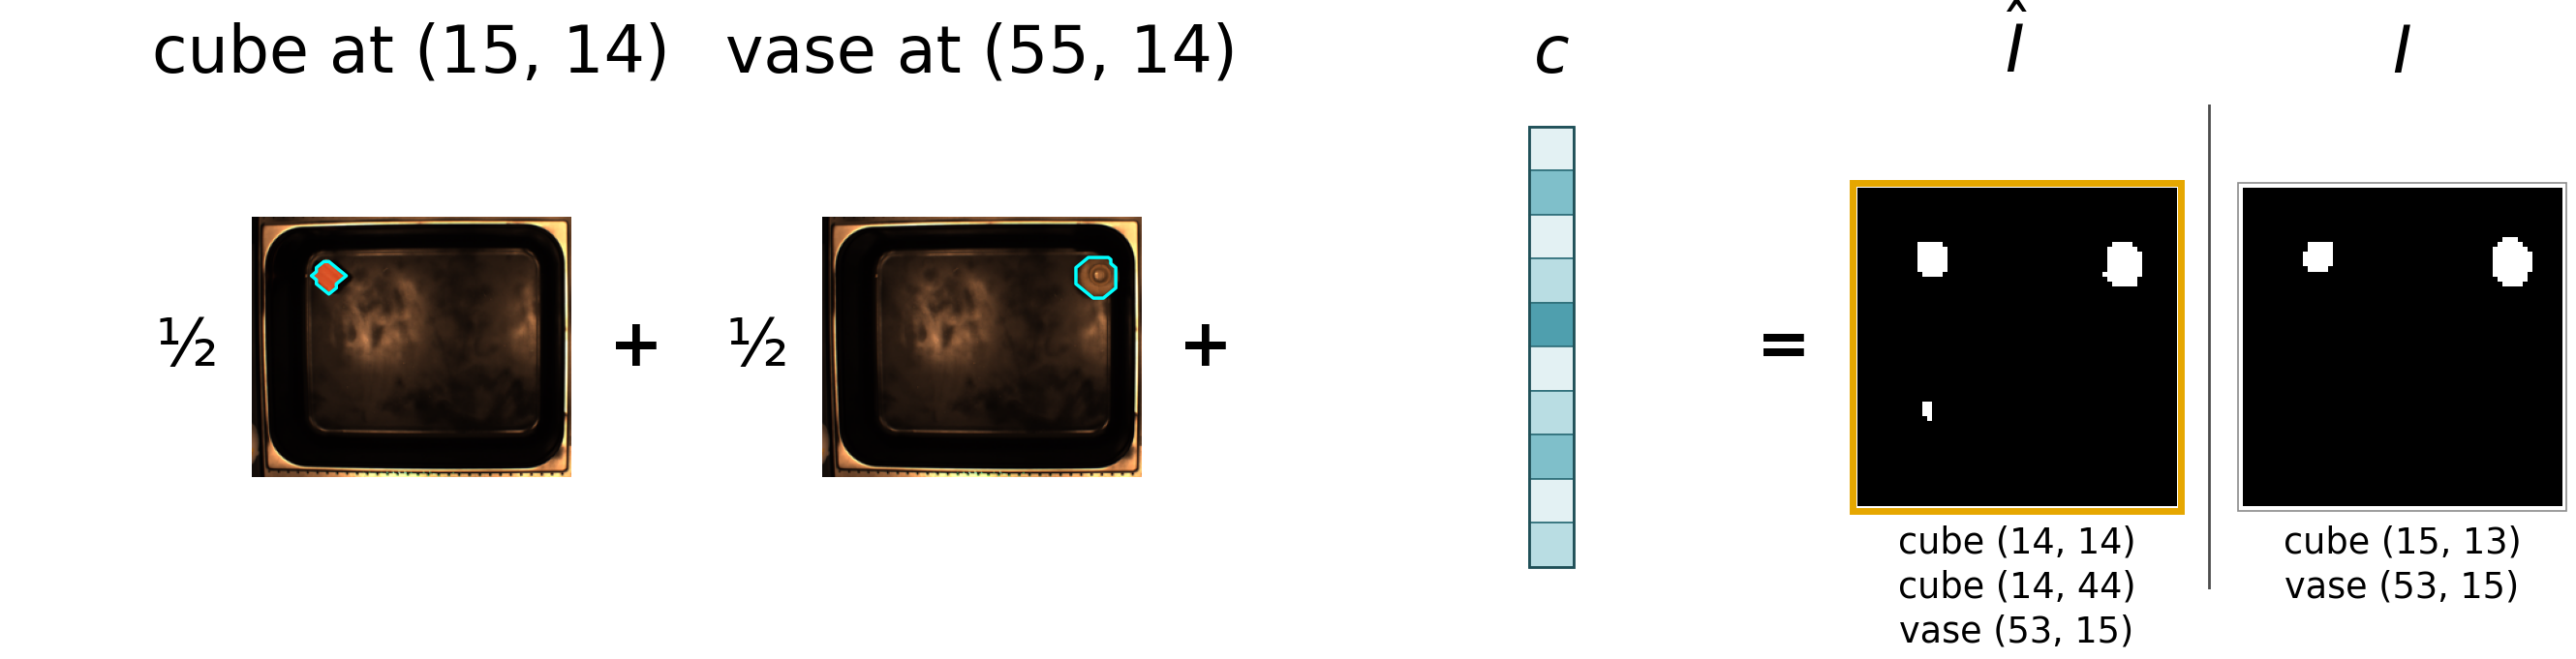

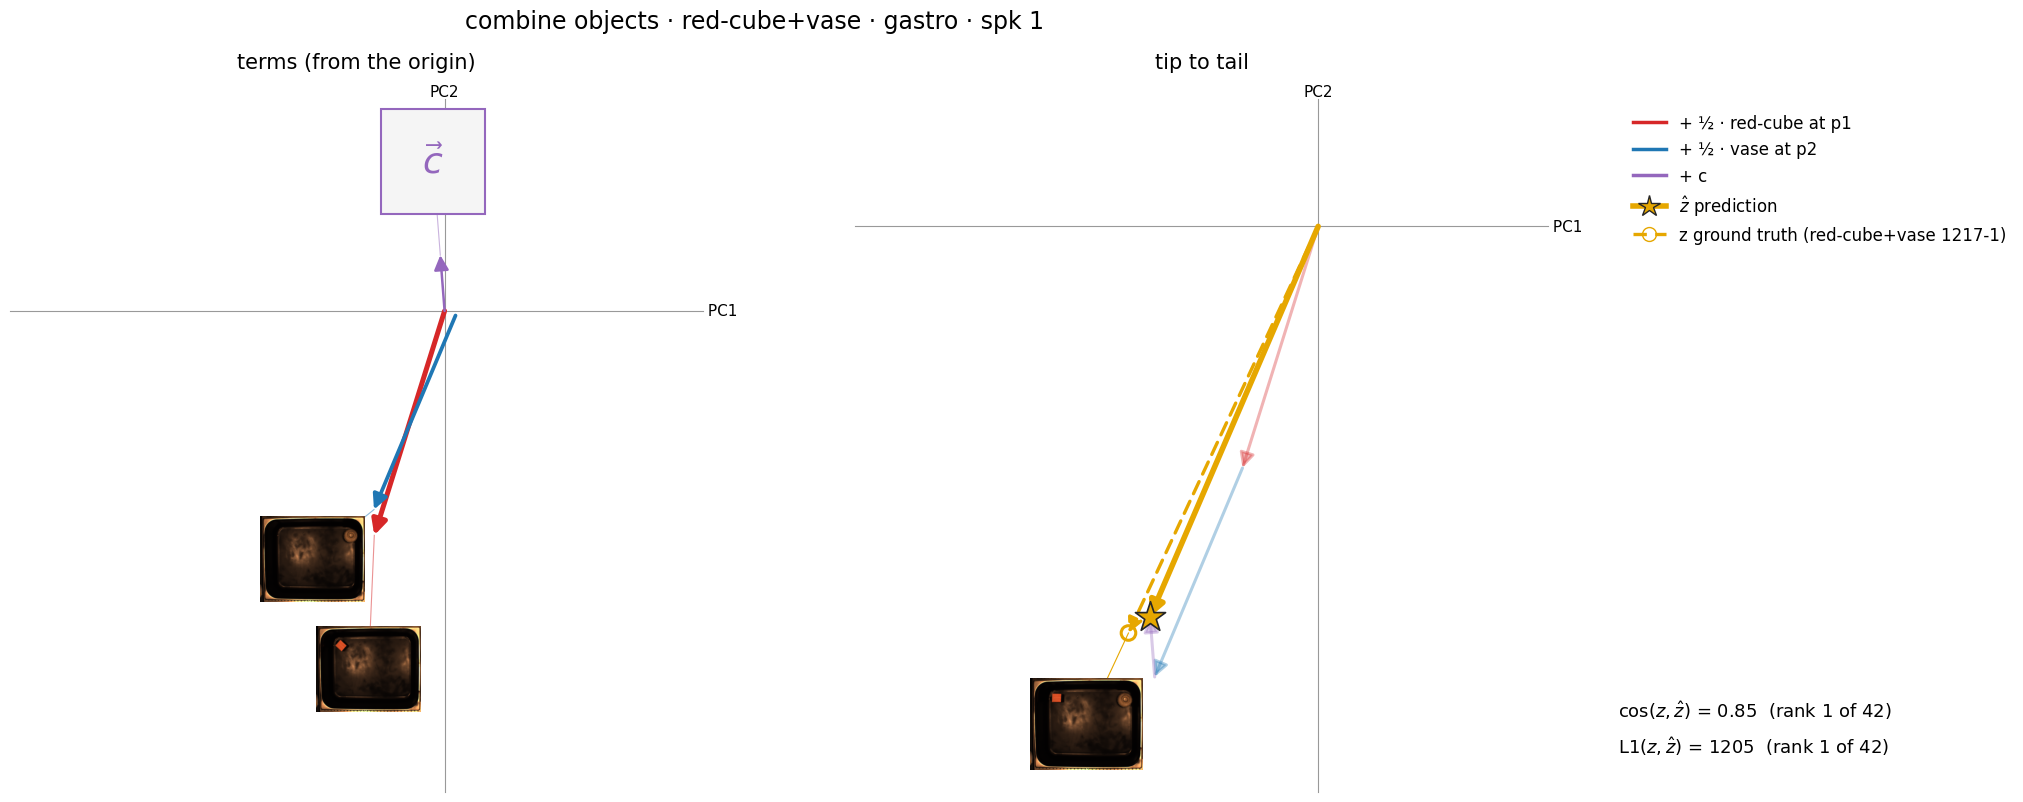

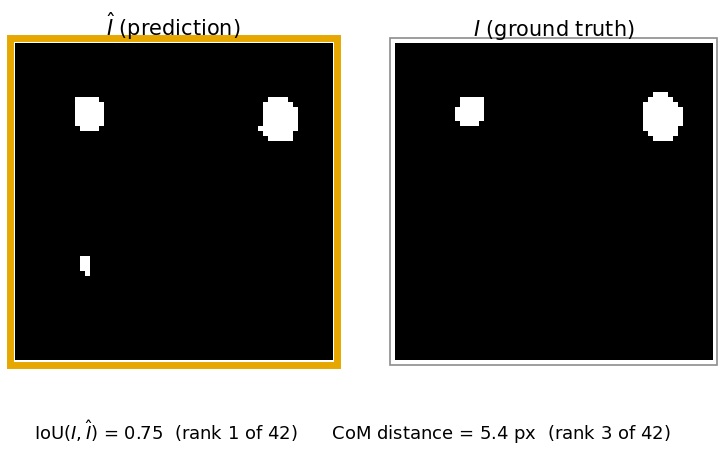

+ ½ red-cube at p1       284-1 · spk 1 · gastro · red-cube
+ ½ vase at p2           546-1 · spk 1 · gastro · vase
+   c                    mean red-cube+vase (n=41) − ½(mean red-cube (n=245) + mean vase (n=219)) in gastro · spk 1
=   target               1217-1 · spk 1 · gastro · red-cube+vase


In [17]:
row = TOP_combine.iloc[0]
plot_eqn(row)
plot_pca(row)
plot_layouts(row)
print_samples(row)

### combine_objects_2

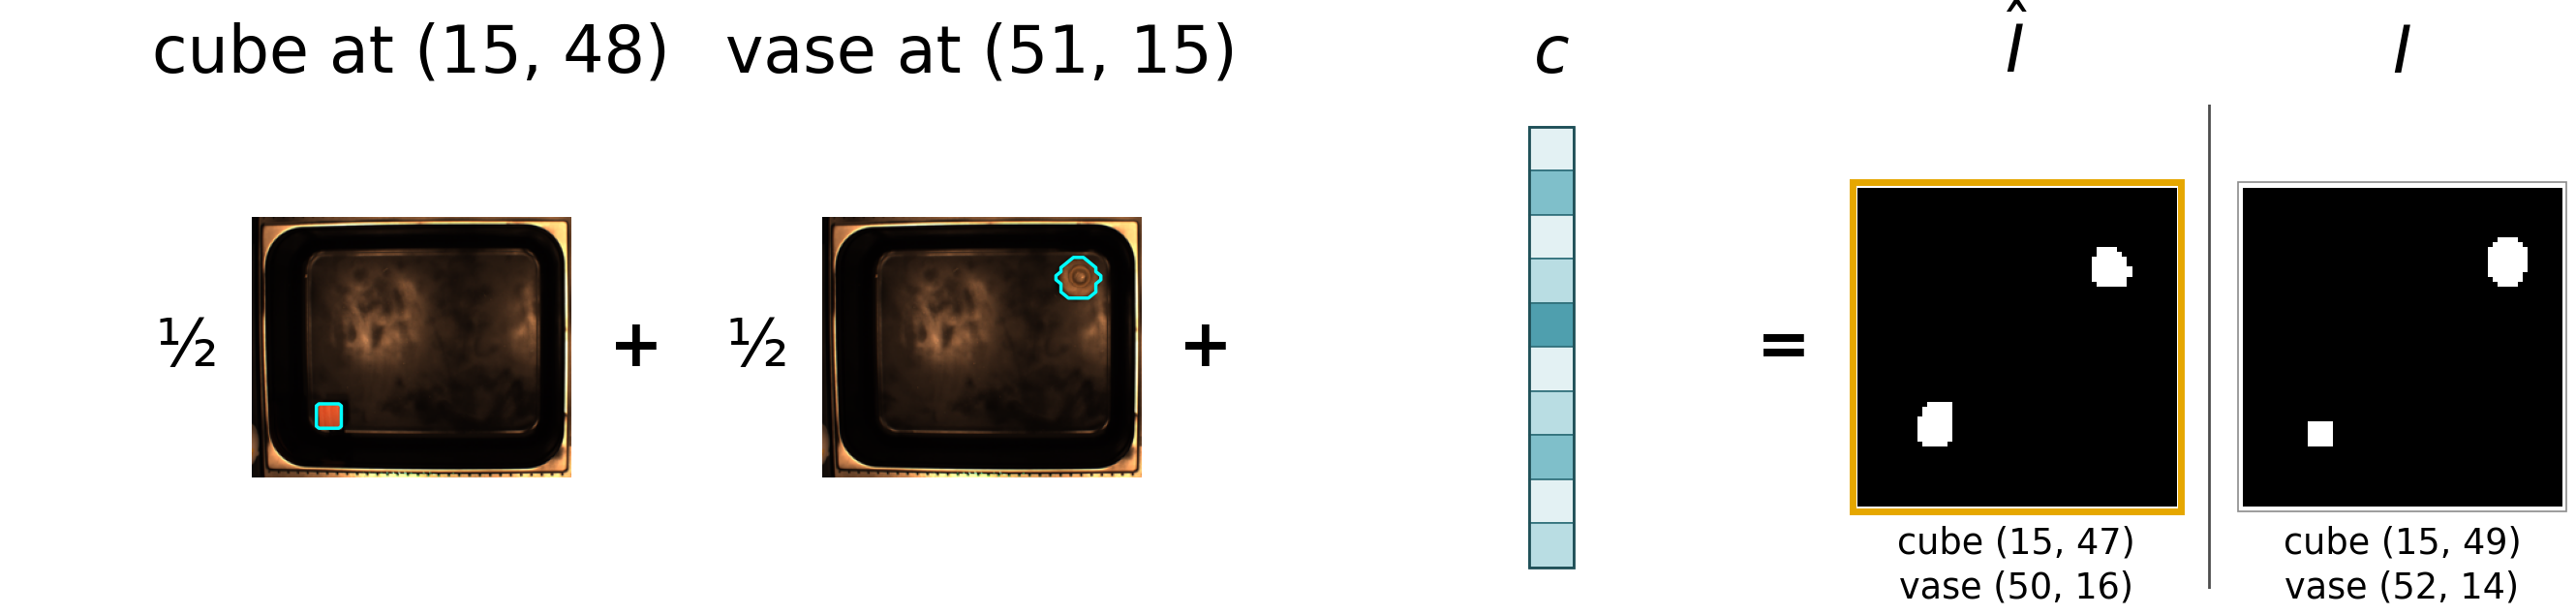

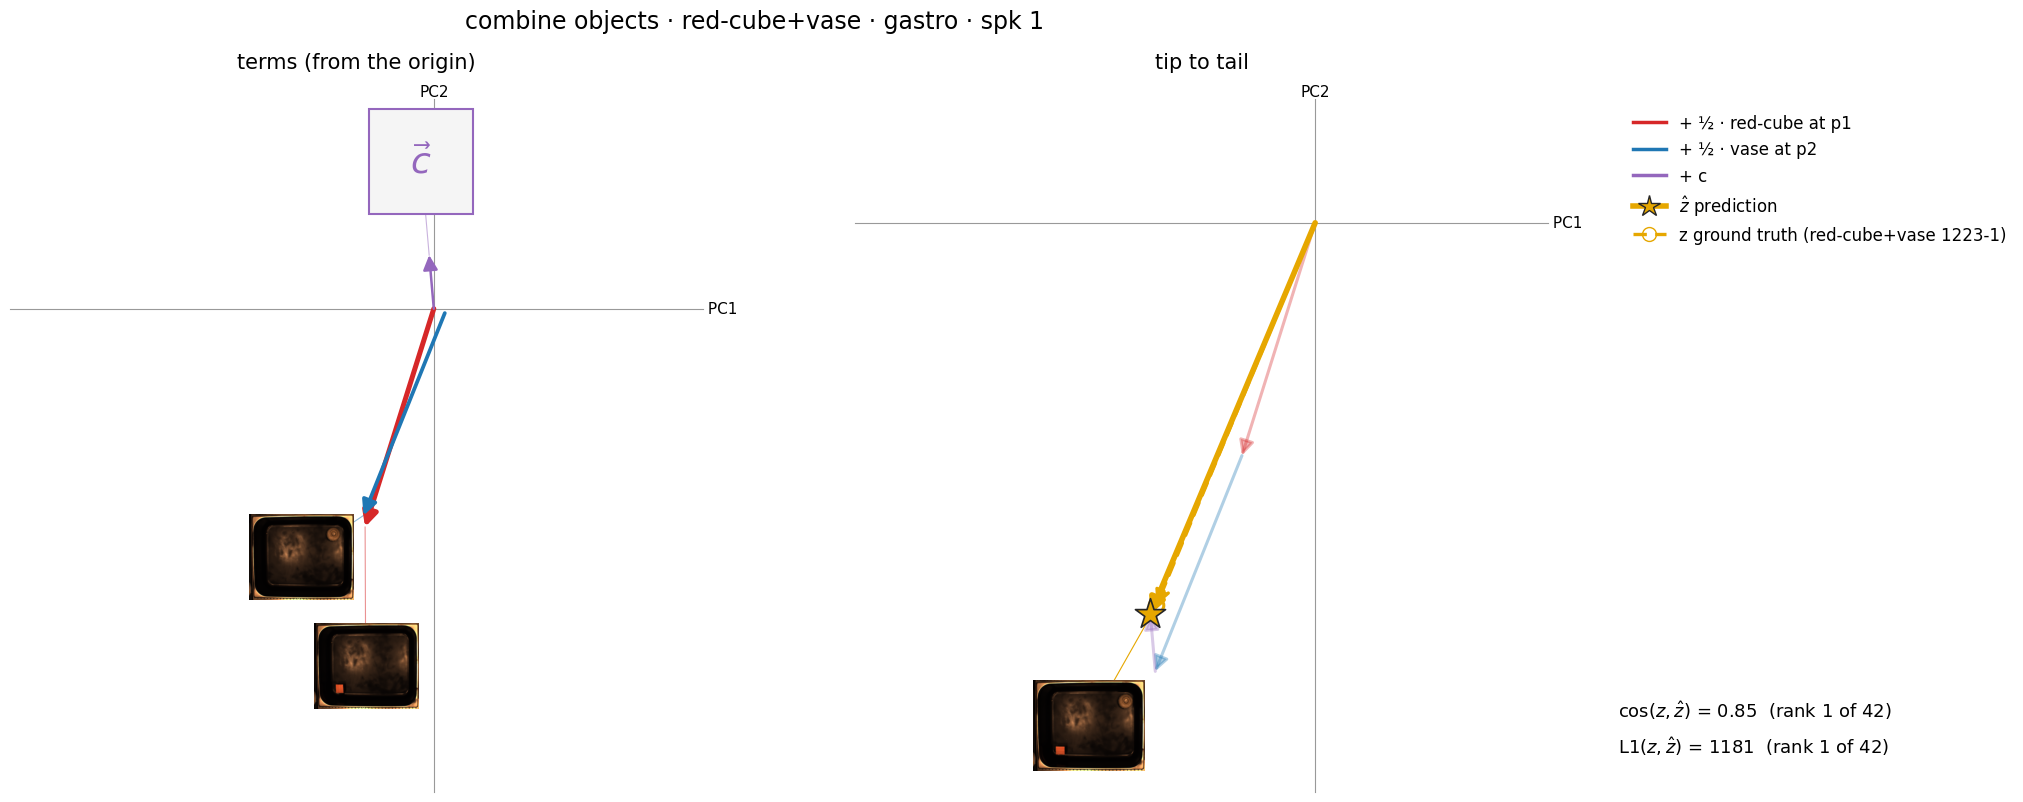

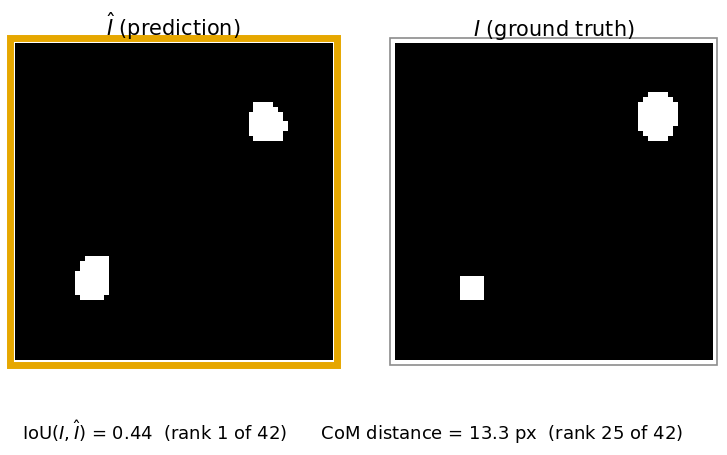

+ ½ red-cube at p1       117-1 · spk 1 · gastro · red-cube
+ ½ vase at p2           576-1 · spk 1 · gastro · vase
+   c                    mean red-cube+vase (n=41) − ½(mean red-cube (n=245) + mean vase (n=219)) in gastro · spk 1
=   target               1223-1 · spk 1 · gastro · red-cube+vase


In [18]:
row = TOP_combine.iloc[1]
plot_eqn(row)
plot_pca(row)
plot_layouts(row)
print_samples(row)

### combine_objects_3

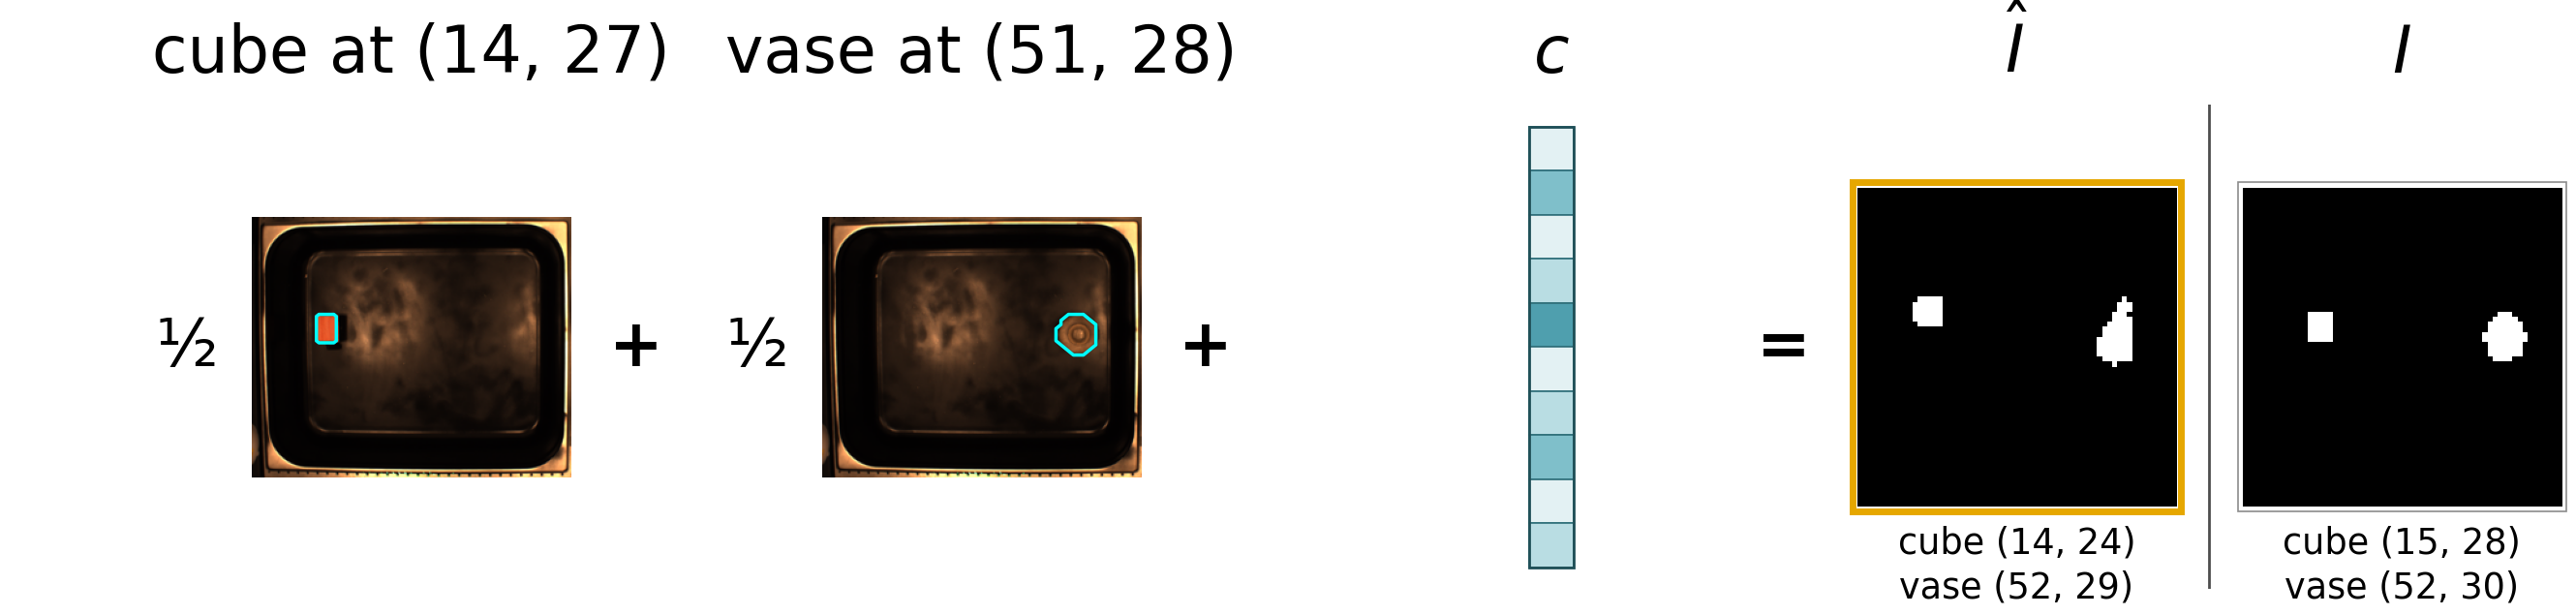

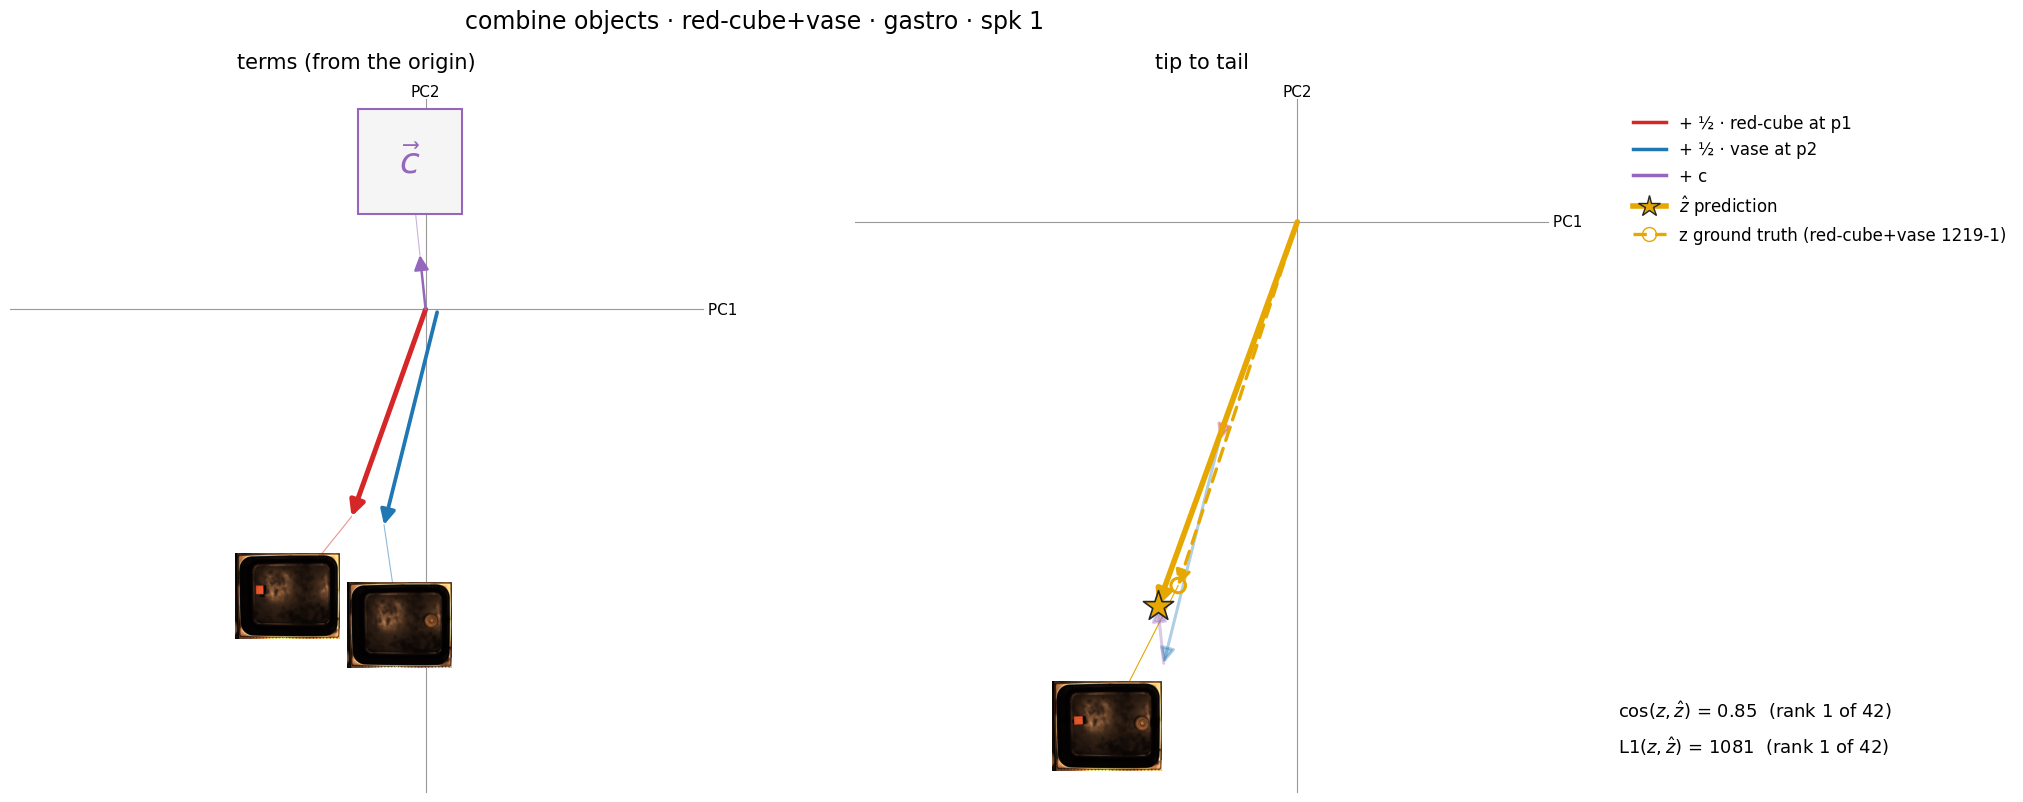

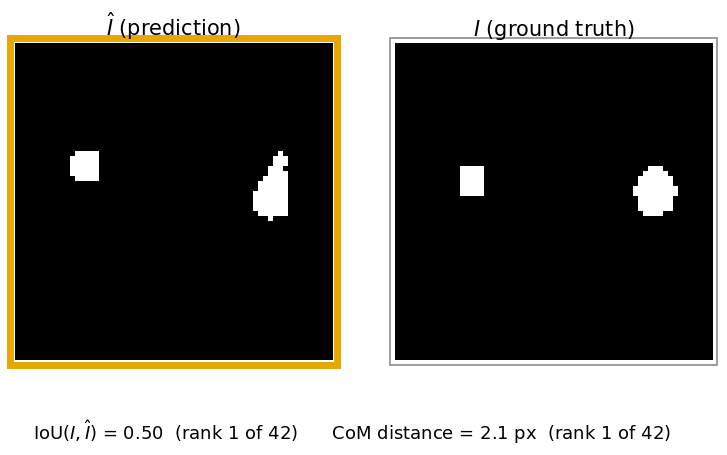

+ ½ red-cube at p1       121-1 · spk 1 · gastro · red-cube
+ ½ vase at p2           577-1 · spk 1 · gastro · vase
+   c                    mean red-cube+vase (n=41) − ½(mean red-cube (n=245) + mean vase (n=219)) in gastro · spk 1
=   target               1219-1 · spk 1 · gastro · red-cube+vase


In [19]:
row = TOP_combine.iloc[2]
plot_eqn(row)
plot_pca(row)
plot_layouts(row)
print_samples(row)

### swap_objects_1

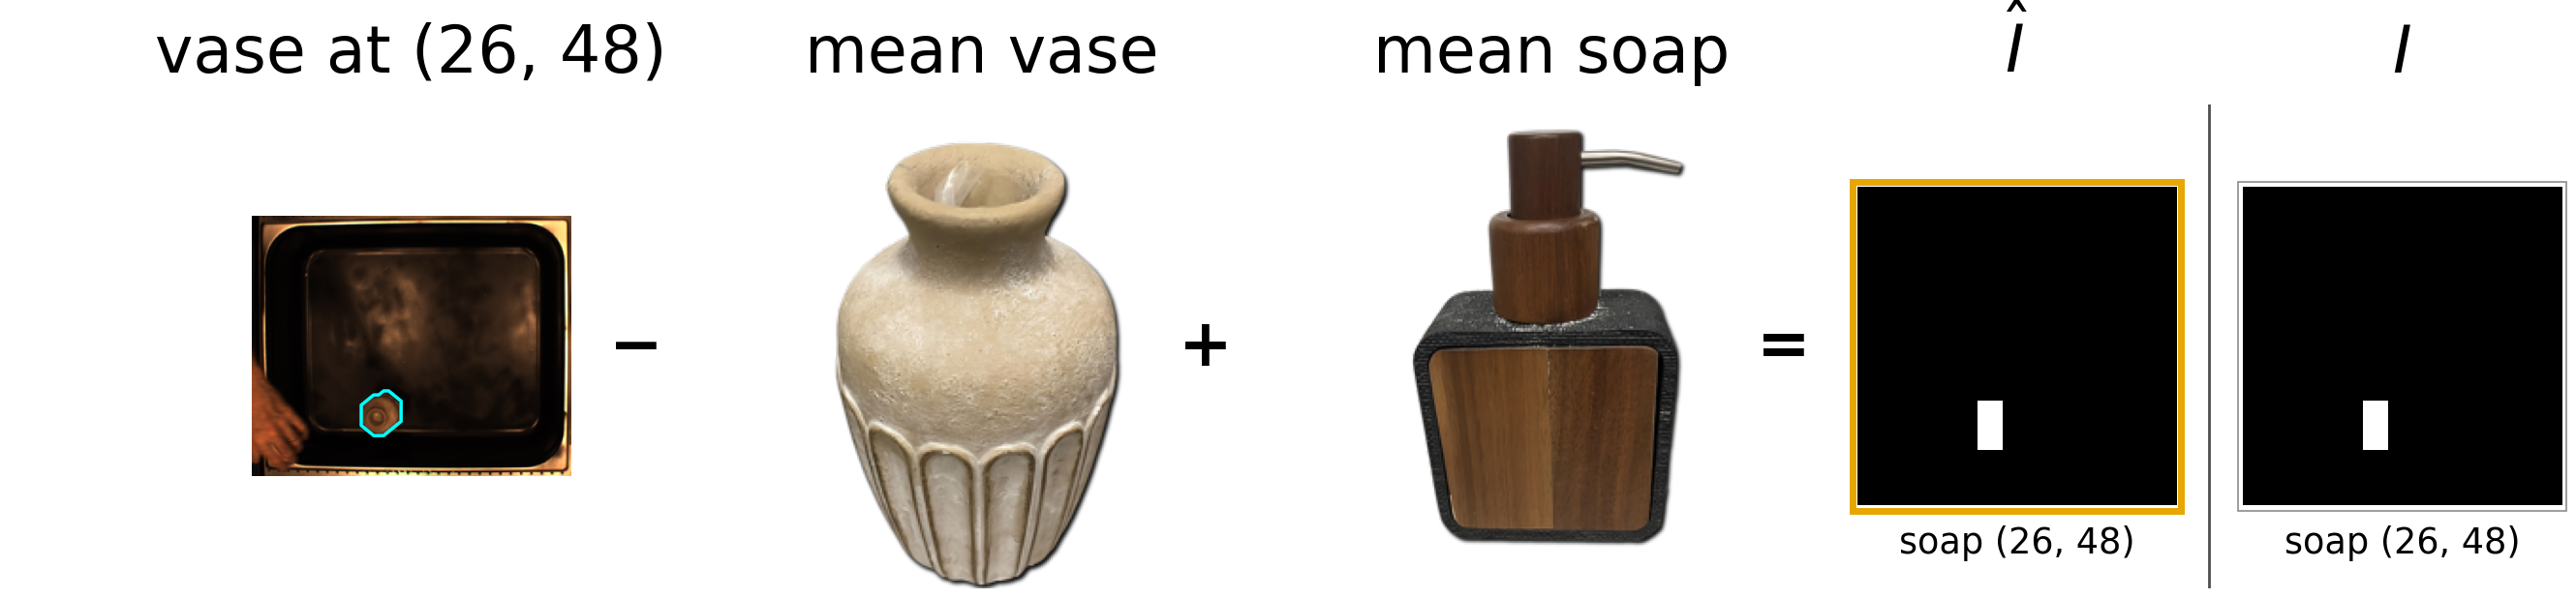

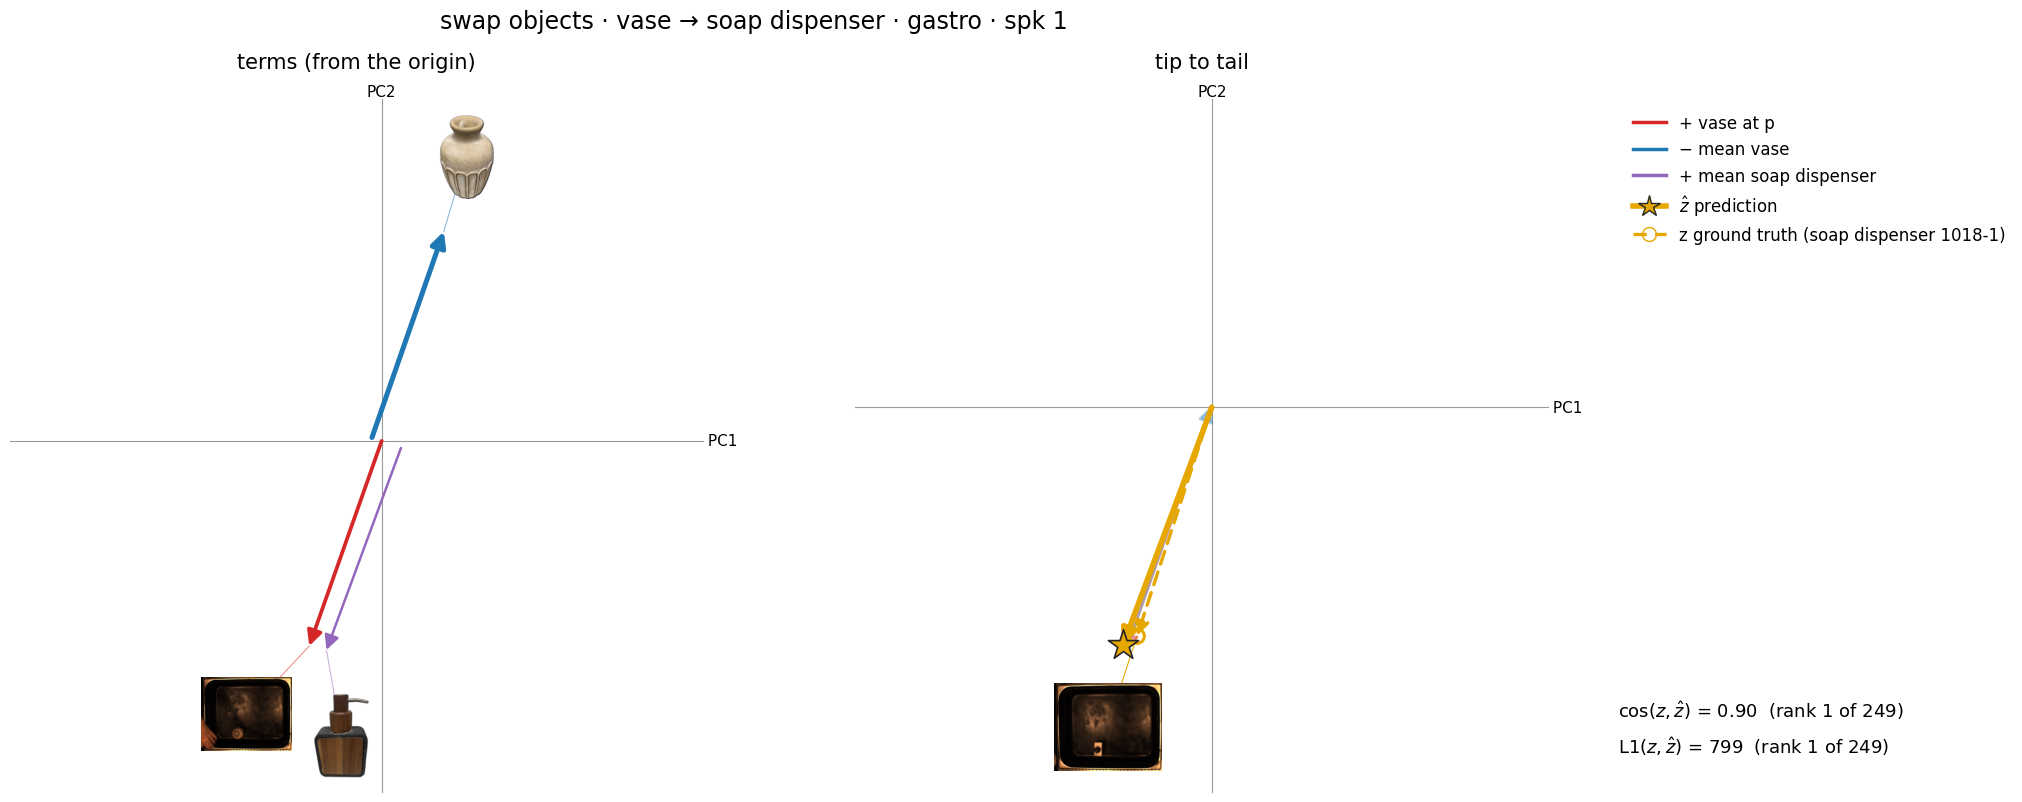

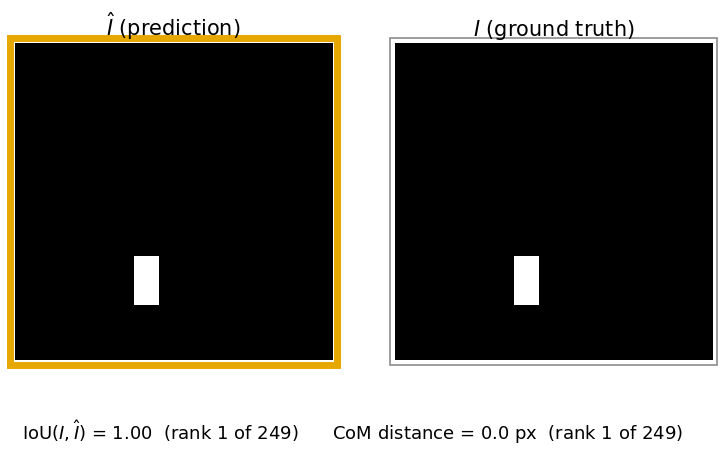

+   vase at p            442-1 · spk 1 · gastro · vase
−   mean vase            mean vase in gastro · spk 1 (n=219)
+   mean soap dispenser  mean soap dispenser in gastro · spk 1 (n=249)
=   target               1018-1 · spk 1 · gastro · soap dispenser


In [20]:
row = TOP_swap.iloc[0]
plot_eqn(row)
plot_pca(row)
plot_layouts(row)
print_samples(row)

### swap_objects_2

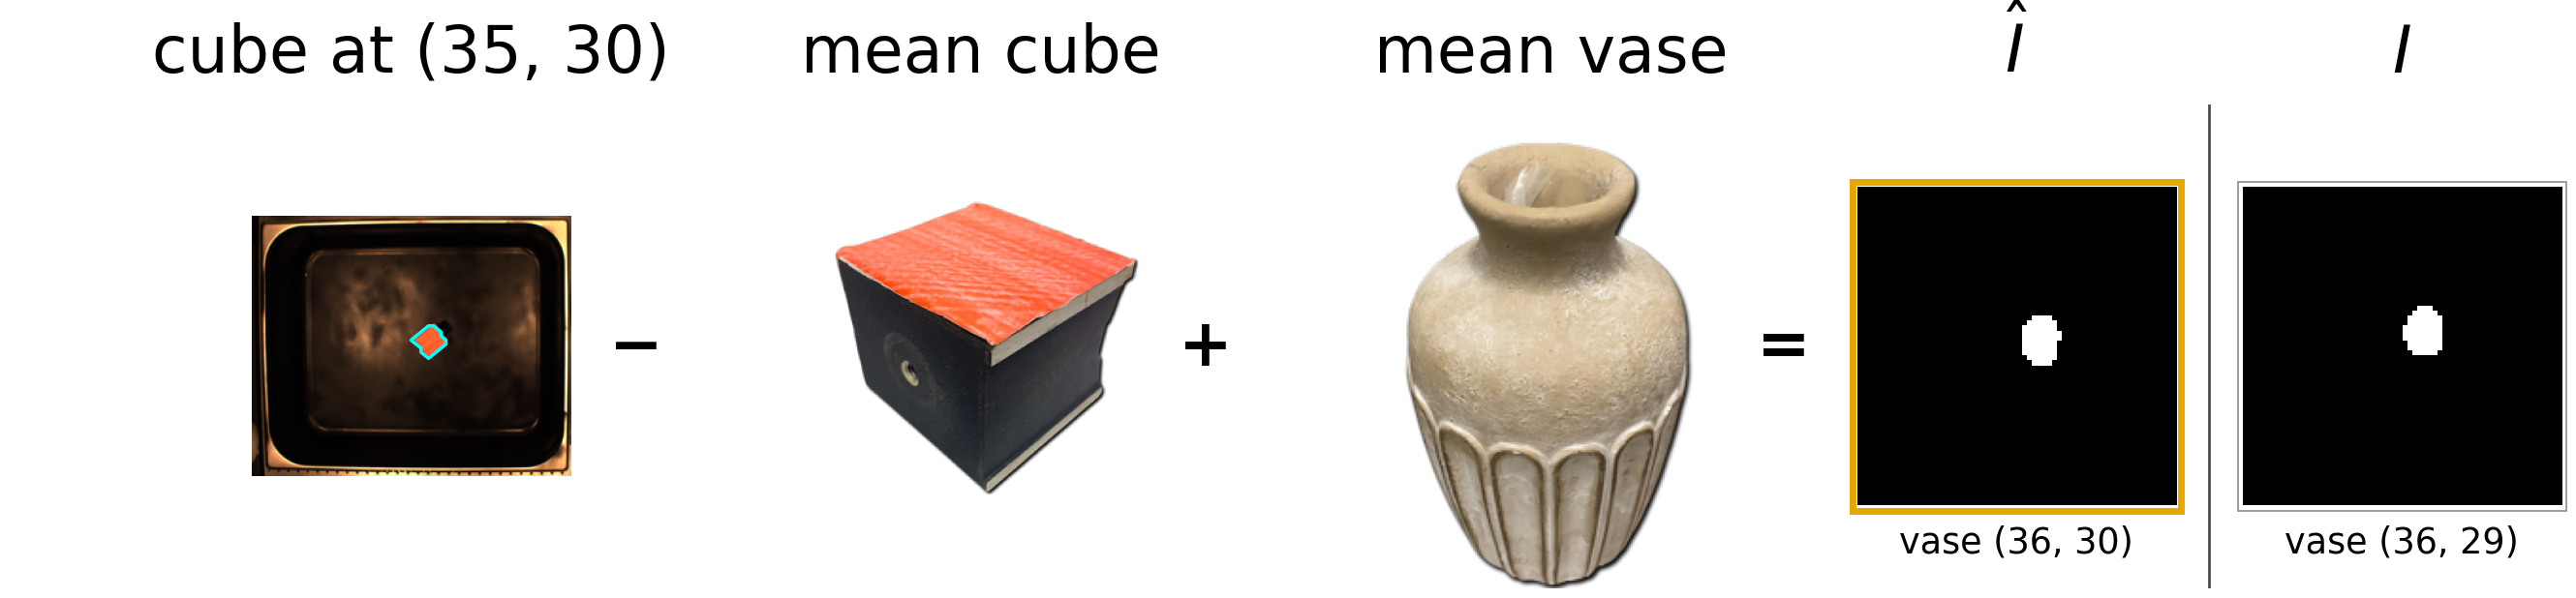

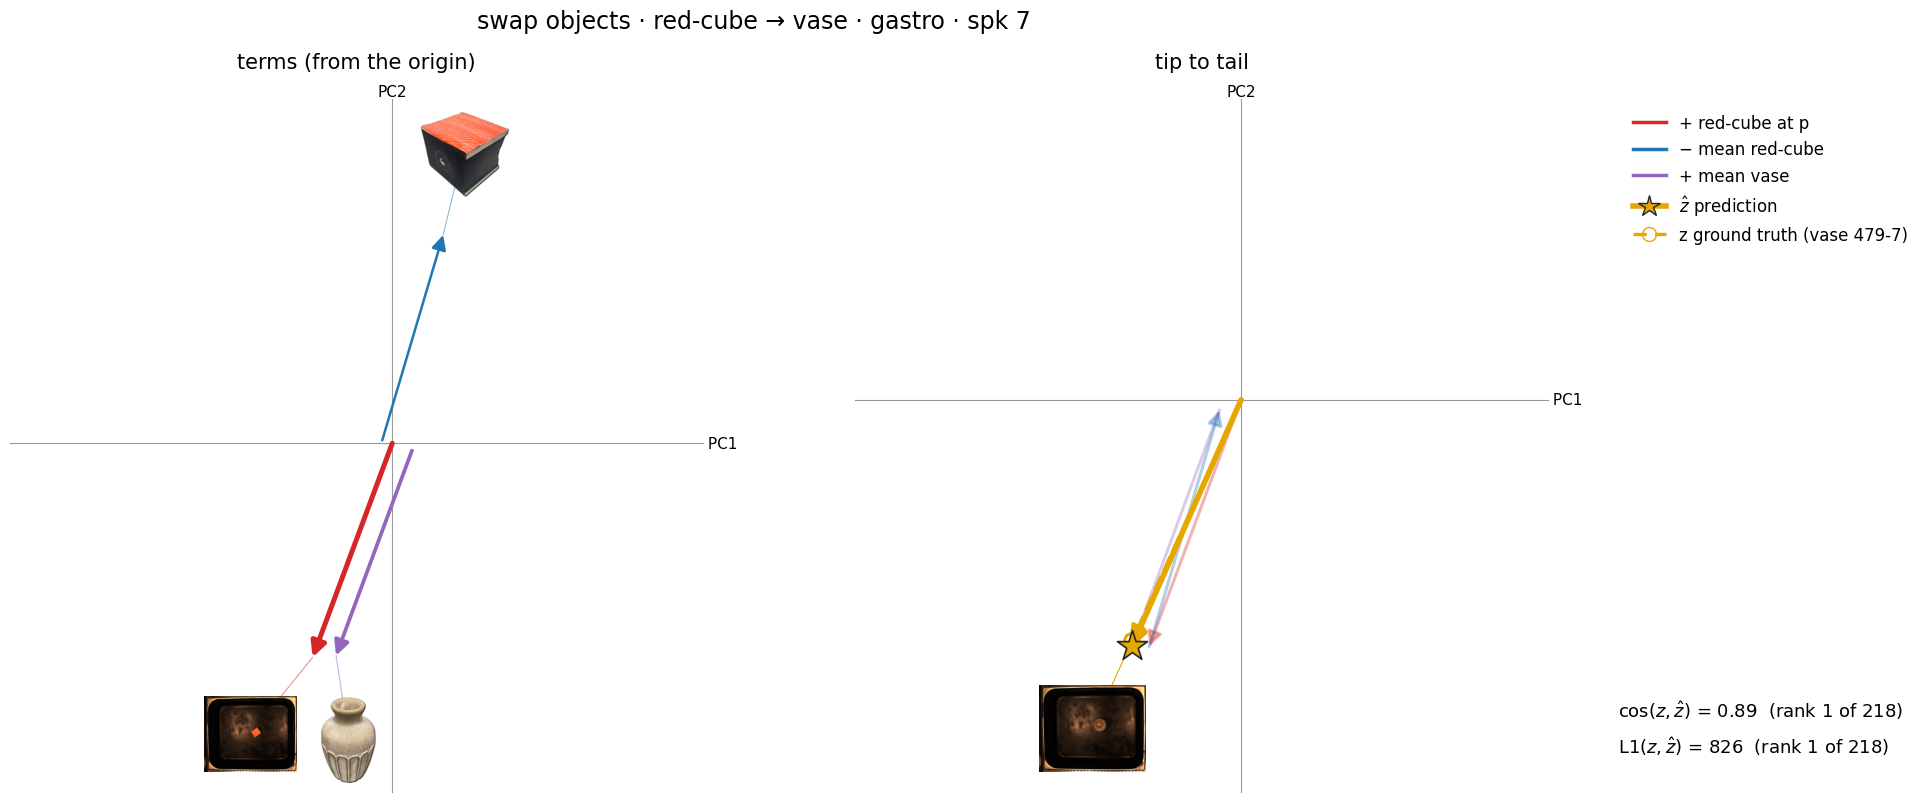

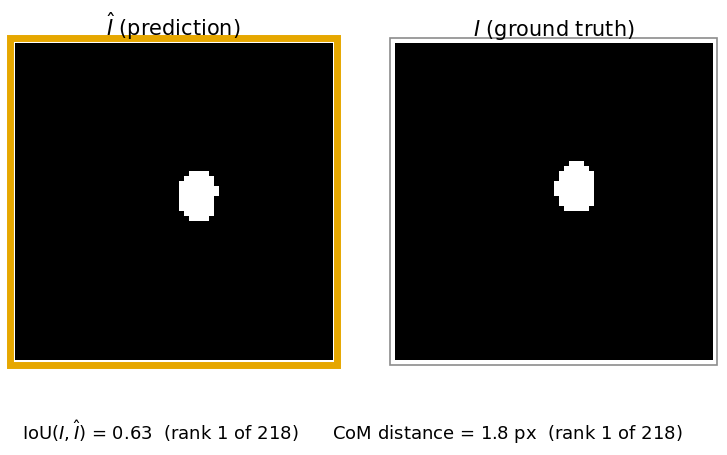

+   red-cube at p        271-7 · spk 7 · gastro · red-cube
−   mean red-cube        mean red-cube in gastro · spk 7 (n=245)
+   mean vase            mean vase in gastro · spk 7 (n=217)
=   target               479-7 · spk 7 · gastro · vase


In [21]:
row = TOP_swap.iloc[1]
plot_eqn(row)
plot_pca(row)
plot_layouts(row)
print_samples(row)

### swap_objects_3

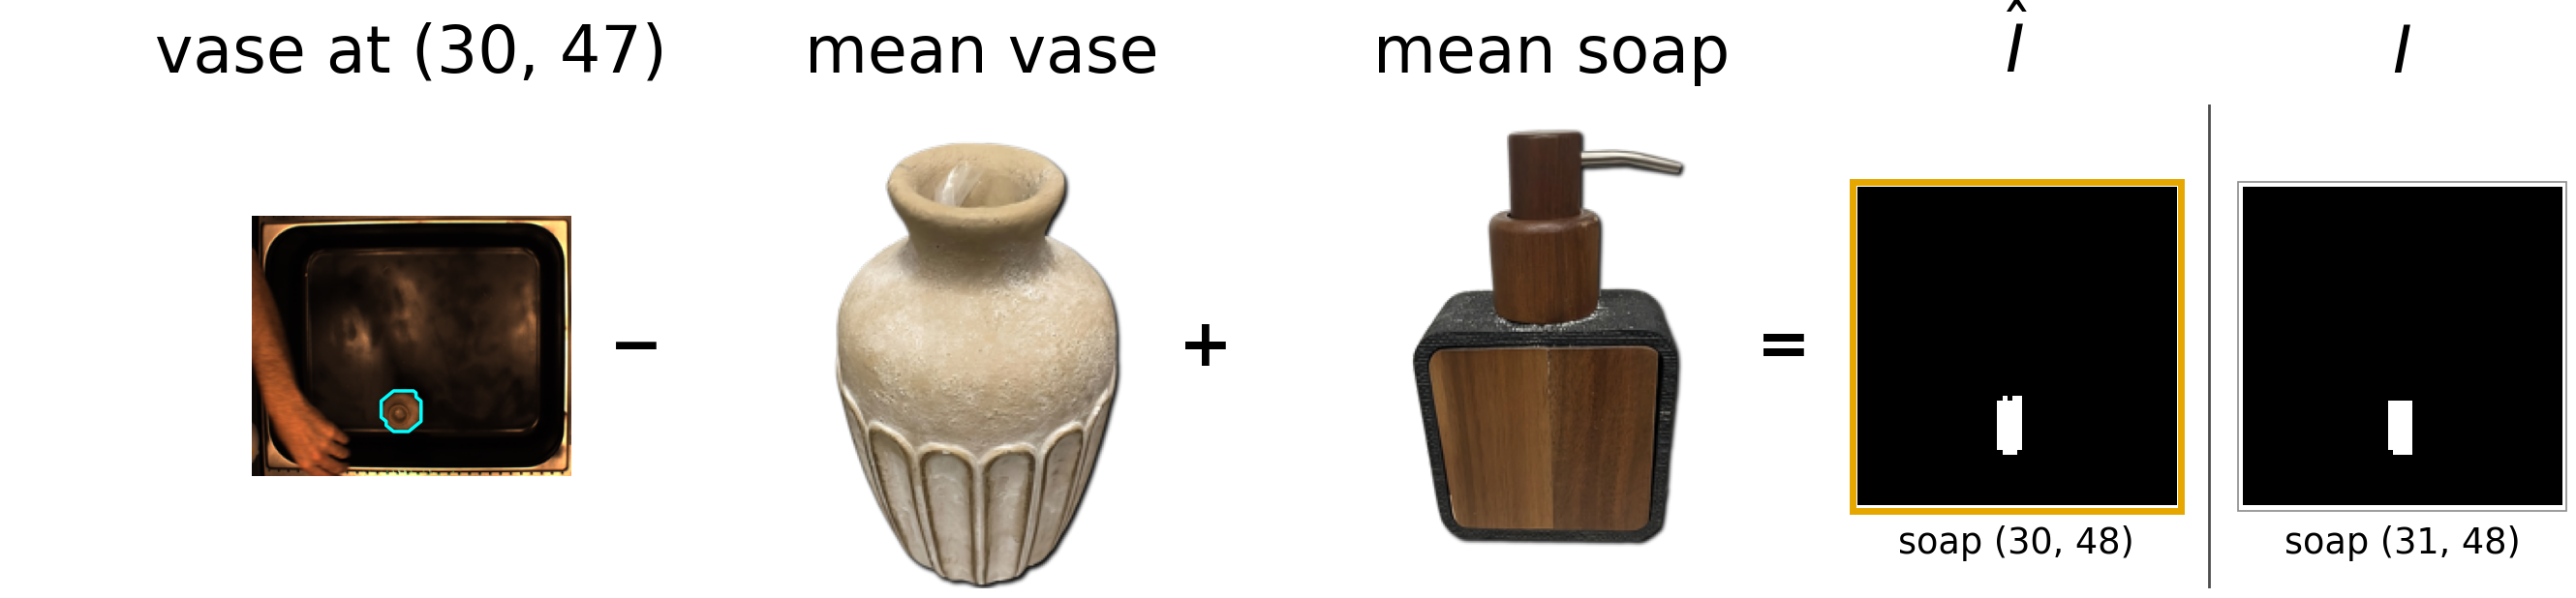

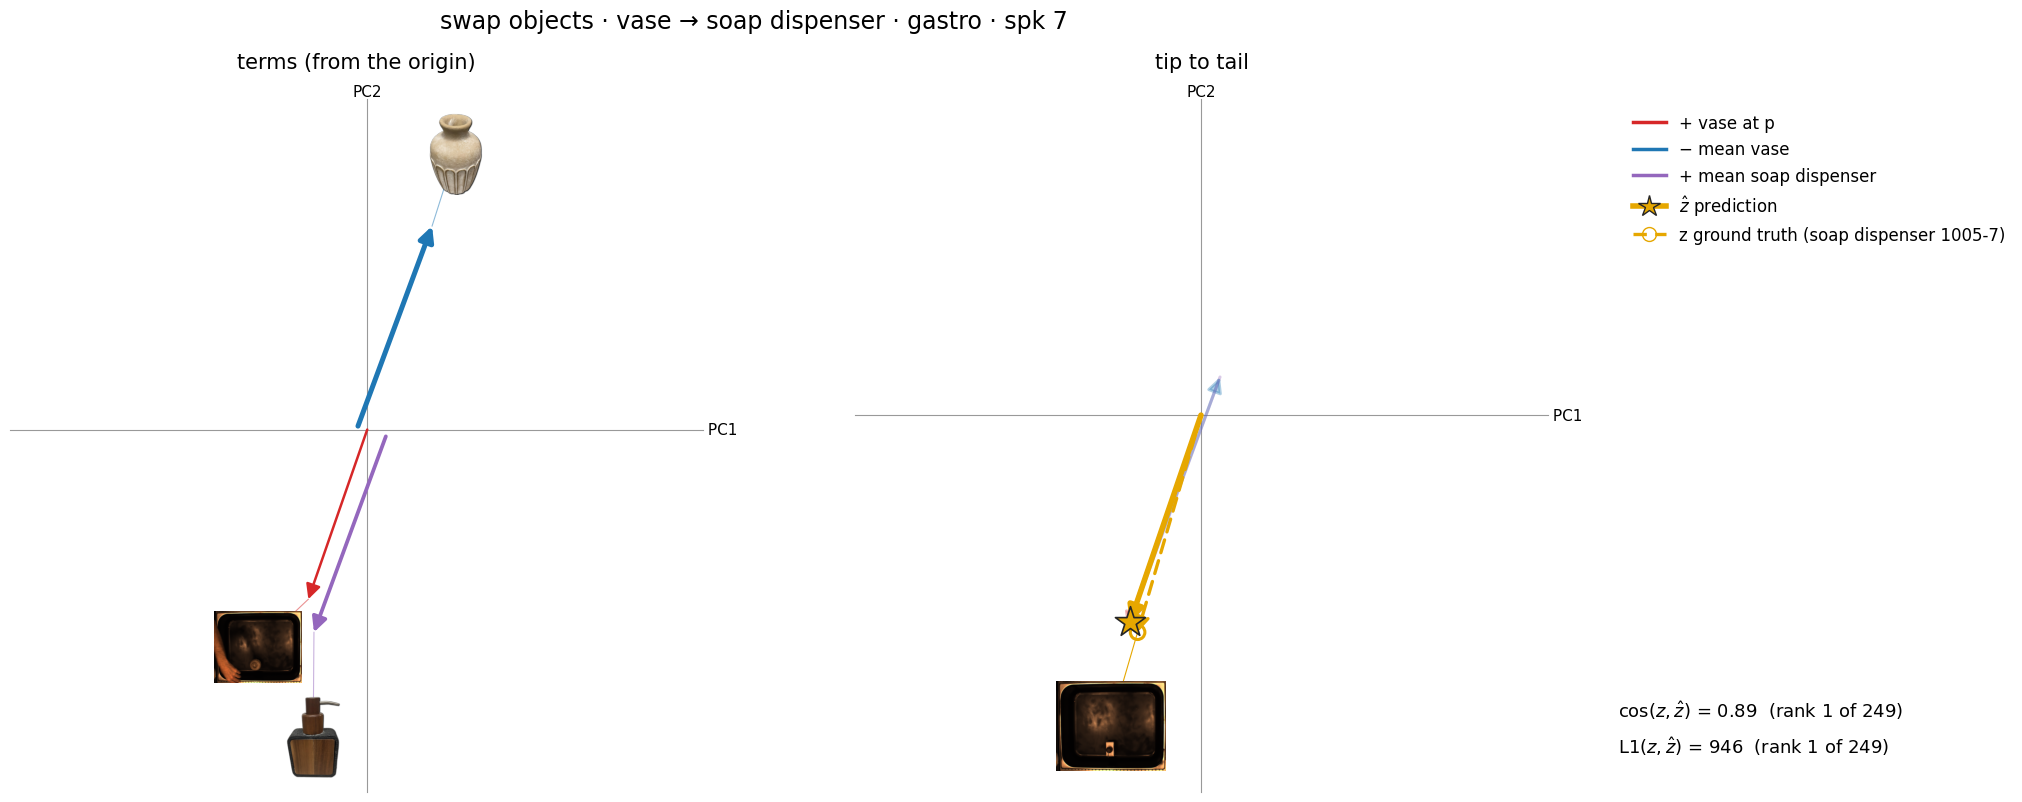

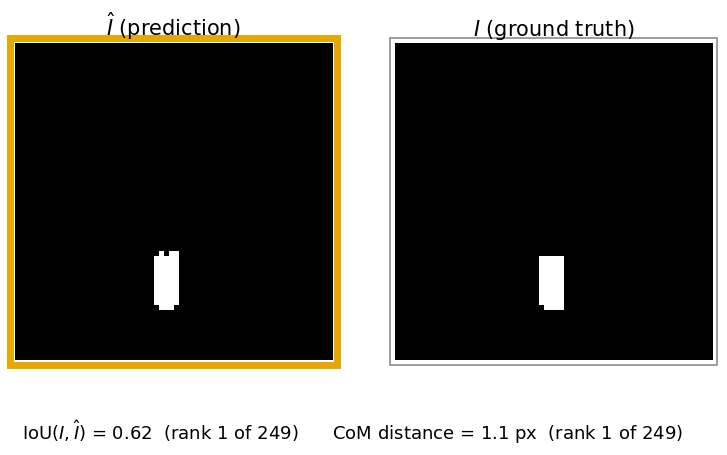

+   vase at p            469-7 · spk 7 · gastro · vase
−   mean vase            mean vase in gastro · spk 7 (n=218)
+   mean soap dispenser  mean soap dispenser in gastro · spk 7 (n=250)
=   target               1005-7 · spk 7 · gastro · soap dispenser


In [22]:
row = TOP_swap.iloc[2]
plot_eqn(row)
plot_pca(row)
plot_layouts(row)
print_samples(row)

### combine_objects_nb139: the nb139 goal-combine best_1 recording (red-cube+vase · plastic · spk 3 · target 2788-3)
nb141 builds ½·obj1 + ½·obj2 from the single recording nearest each part (nb139 searched the K×K nearest pairs for the best one), so the two input recordings can differ from nb139's (2492-3, 2214-3).

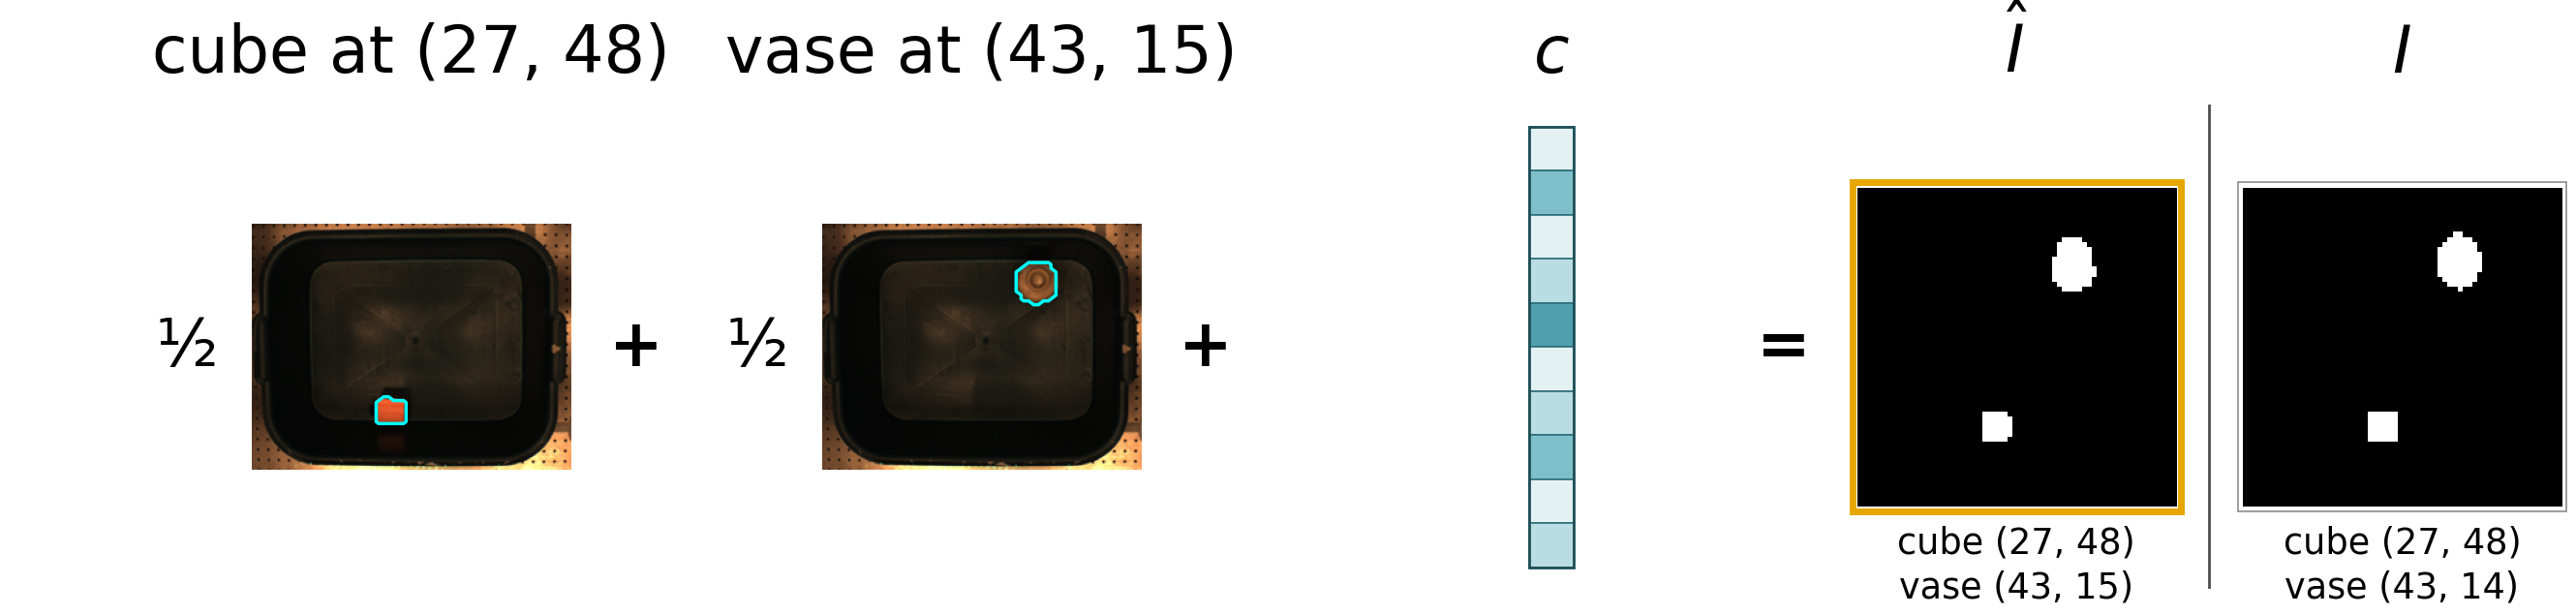

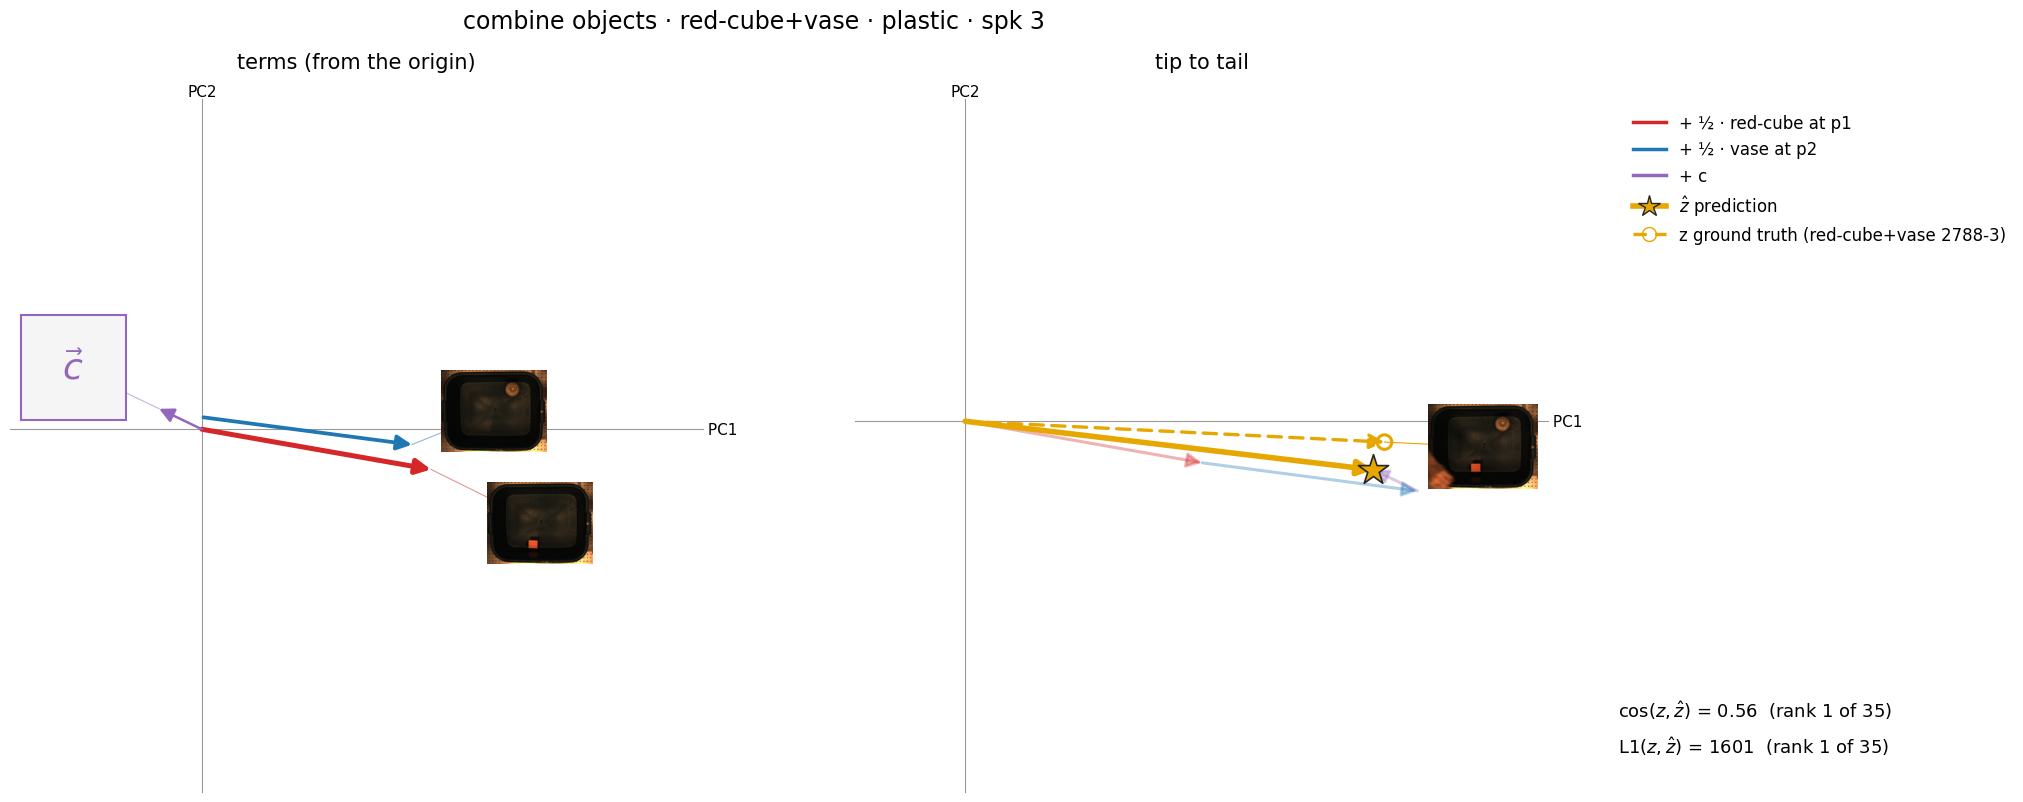

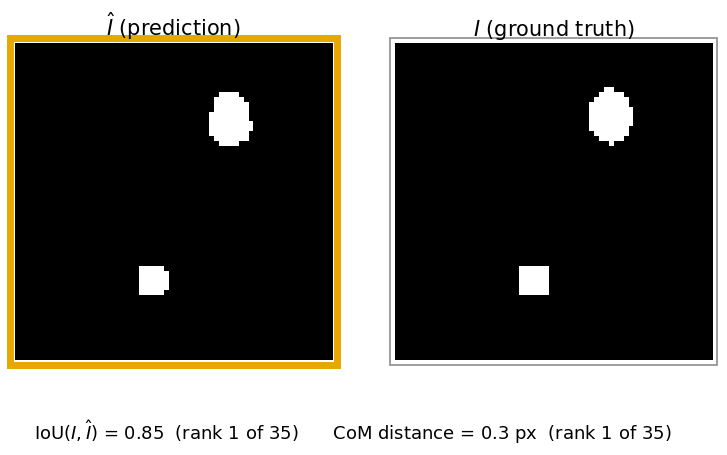

+ ½ red-cube at p1       2492-3 · spk 3 · plastic · red-cube
+ ½ vase at p2           2243-3 · spk 3 · plastic · vase
+   c                    mean red-cube+vase (n=34) − ½(mean red-cube (n=252) + mean vase (n=203)) in plastic · spk 3
=   target               2788-3 · spk 3 · plastic · red-cube+vase


In [23]:
row = S_combine[(S_combine.sid == "2788-3") & (S_combine.box == "plastic") & (S_combine.speaker == 3)].iloc[0]
row = row.copy()
row["fig_name"] = "combine_objects_nb139"
plot_eqn(row)
plot_pca(row)
plot_layouts(row)
print_samples(row)

## Findings (decres-rescale-aug10-v1, fresh nb141 cache)
Every instance counts here, not just the best config. **exact** = the rank of the one target recording, with the other recordings at its position dropped (the main number). **any** = nb139's rule: a hit if any recording within R_PX of p is the closest.

| task | box | n | rank@1 cos exact / any | rank@1 L2 exact / any | rank@1 IoU | mean IoU(I, Î) | median candidates |
|---|---|---|---|---|---|---|---|
| combine | plastic | 460 | .80 / .80 | .73 / .73 | .88 | .56 | 80 |
| combine | gastro | 338 | .61 / .61 | .52 / .52 | .60 | .34 | 71 |
| combine | cardboard | 705 | .31 / .31 | .21 / .21 | .49 | .34 | 94 |
| **combine** | all | 1503 | **.53 / .53** | **.44 / .44** | .63 | **.41** | |
| swap | plastic | 10309 | .29 / .44 | .28 / .44 | .70 | .69 | 251 |
| swap | gastro | 6914 | .25 / .37 | .26 / .38 | .60 | .63 | 248 |
| swap | cardboard | 11791 | .14 / .29 | .12 / .25 | .51 | .59 | 301 |
| **swap** | all | 29014 | **.22 / .36** | **.21 / .35** | .60 | **.63** | |

- **Exact vs any.** For combine the two rules agree: almost no other pair recording shares the same arrangement. For swap, "any" adds about .14, because 1–6 recordings of the target object sit within 2 px of p. nb139's .78 (plastic spk 7, red-cube → vase) used the "any" rule.
- **Combine objects** works for red-cube+vase in plastic: rank@1 cos .96, IoU .59. It is weak for green-cube+red-cube in cardboard (.17 / .25), where two red-cube recordings stand in for one green and one red cube.
- **Swap objects** rarely retrieves the exact latent (rank@1 about .2 of ~250), but the decoded layout is much better: IoU .63, IoU rank@1 .60. ẑ gets the object's place right more often than it lands on the exact latent.
- Cardboard is the weakest box for both tasks; plastic is the best.
- In the global 2-D PCA, z and ẑ almost overlap for every top instance. Two large terms dominate both PCs, so the PCA view flatters the analogy; the ranks are the honest number.
- The centred cosine is symmetric under reversal: A→B and B→A on the same two recordings get the same cos. `top()` keeps one of each mirrored pair.